# BERTopic en español: la primera parte de Don Quijote

Este notebook contiene todo el proyecto: segmentación, embeddings, dos configuraciones y análisis.
Ejecuta las celdas en orden. El corpus y las stopwords están en `data/`; las tablas y figuras se guardan en `results/`.
La primera ejecución descarga el encoder; las siguientes reutilizan sus pesos locales.

Se utiliza la primera parte (1605), de 52 capítulos, de Miguel de Cervantes Saavedra,
obtenida de [Project Gutenberg](https://www.gutenberg.org/ebooks/2000).
El texto es distinto de las reseñas de Letterboxd del [repositorio de referencia](https://github.com/ErikJajan/BERTopic).
La implementación es propia, con asistencia de IA para código, nombres e interpretación.

## 1. Preparación del entorno

In [1]:
from pathlib import Path
import os
import random
import re

ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
# Mantener los pesos y las cachés dentro del proyecto.
for variable in ["HF_HOME", "MPLCONFIGDIR", "NUMBA_CACHE_DIR"]:
    os.environ.setdefault(variable, str(ROOT / ".cache" / variable.lower()))
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["NUMBA_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from umap import UMAP

SEED = 42
PREFIX = "query: "
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)

/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Embeddings y segmentación

Se elige [`intfloat/multilingual-e5-small`](https://huggingface.co/intfloat/multilingual-e5-small)
porque incluye español, produce embeddings semánticos de 384 dimensiones y admite 512 tokens.
Ese límite permite conservar más párrafos completos que un encoder de 128 tokens.
Para clustering, su ficha recomienda el prefijo `query: `; se usa normalización L2.
No se presupone que sea el mejor modelo para el español del Siglo de Oro.

La unidad es **un párrafo**. Se excluyen portadas, prólogos, índices y la segunda parte de la novela.
Solo los párrafos de más de 512 tokens se dividen por oraciones o, si hace falta, por palabras.
El límite incluye el prefijo y los tokens especiales. Nunca se unen párrafos distintos.
Después se quitan fragmentos de menos de cinco palabras y duplicados, normalizando espacios y mayúsculas.

In [2]:
encoder = SentenceTransformer(
    "intfloat/multilingual-e5-small",
    revision="614241f622f53c4eeff9890bdc4f31cfecc418b3",
    device="cpu",
)
tokenizer = encoder.tokenizer
LIMIT = encoder.max_seq_length

In [3]:
def extract_chapters(raw):
    text = raw.replace('\r\n', '\n')
    start = re.search(r'^Capítulo primero\.', text, re.M).start()
    end = text.index('Segunda parte del ingenioso caballero don Quijote de la Mancha', start)
    text = text[start:end]
    # La edición de 1605 contiene divisiones internas en «partes»; no son la de 1615.
    text = re.sub(r'^(?:Primera|Segunda|Tercera|Cuarta) parte del ingenioso hidalgo don Quijote de la Mancha\s*$', '', text, flags=re.M)
    matches = list(re.finditer(r'^Capítulo (?:primero|[IVXLCDM]+)\.', text, re.M))
    chapters = []
    for i, match in enumerate(matches):
        block = text[match.start():matches[i+1].start() if i+1 < len(matches) else len(text)].strip()
        heading, body = re.split(r'\n\s*\n', block, maxsplit=1)
        chapters.append((i+1, ' '.join(heading.split()), body))
    if len(chapters) != 52:
        raise ValueError(f'Se esperaban 52 capítulos; hay {len(chapters)}')
    return chapters

def split_long(unit, tokenizer, limit):
    """Dividir solo las unidades largas y conservar exactamente las palabras."""
    if len(tokenizer.encode(PREFIX + unit)) <= limit:
        return [unit]
    sentences = re.split(r'(?<=[.!?;])\s+', unit)
    if len(sentences) > 1:
        return [part for sentence in sentences for part in split_long(sentence, tokenizer, limit)]
    parts, current = [], ''
    for word in unit.split():
        candidate = (current + ' ' + word).strip()
        if len(tokenizer.encode(PREFIX + candidate)) > limit:
            parts.append(current)
            current = word
        else:
            current = candidate
    if current:
        parts.append(current)
    return parts

def segment_chapter(body, tokenizer, limit=512):
    paragraphs = [' '.join(p.split()) for p in re.split(r'\n\s*\n', body) if p.strip()]
    segments = []
    for paragraph_id, paragraph in enumerate(paragraphs, 1):
        current = ''
        for unit in split_long(paragraph, tokenizer, limit):
            candidate = (current + ' ' + unit).strip()
            if current and len(tokenizer.encode(PREFIX + candidate)) > limit:
                segments.append((current, paragraph_id, paragraph_id))
                current = ''
            current = (current + ' ' + unit).strip()
        if current:
            segments.append((current, paragraph_id, paragraph_id))
    return segments

In [4]:
chapters = extract_chapters((DATA / "quijote.txt").read_text(encoding="utf-8-sig"))
rows = []
paragraph_count = long_paragraph_count = 0
for number, title, body in chapters:
    paragraphs = [p for p in re.split(r"\n\s*\n", body) if p.strip()]
    paragraph_count += len(paragraphs)
    long_paragraph_count += sum(
        len(tokenizer.encode(PREFIX + " ".join(p.split()))) > LIMIT for p in paragraphs
    )
    for sequence, (text, first, last) in enumerate(segment_chapter(body, tokenizer, LIMIT), 1):
        rows.append(dict(
            segment_id=f"P1-C{number:02d}-S{sequence:04d}", chapter=number,
            paragraph=first, text=text, words=len(text.split()),
            tokens=len(tokenizer.encode(PREFIX + text)),
        ))

segments = pd.DataFrame(rows)
before = len(segments)
short = int((segments.words < 5).sum())
segments = segments[segments.words >= 5].copy()
duplicates = int(segments.text.str.casefold().duplicated().sum())
segments = segments.loc[~segments.text.str.casefold().duplicated()].reset_index(drop=True)
# Comprobaciones mínimas de los requisitos de entrada.
assert len(segments) >= 500
assert segments.tokens.max() <= LIMIT

display(pd.Series({
    "Párrafos originales": paragraph_count,
    "Párrafos divididos": long_paragraph_count,
    "Segmentos antes de filtrar": before,
    "Eliminados por longitud": short,
    "Duplicados eliminados": duplicates,
    "Segmentos finales": len(segments),
}))
display(segments[["words", "tokens"]].describe())

Token indices sequence length is longer than the specified maximum sequence length for this model (547 > 512). Running this sequence through the model will result in indexing errors


Párrafos originales           1980
Párrafos divididos              75
Segmentos antes de filtrar    2072
Eliminados por longitud         22
Duplicados eliminados            4
Segmentos finales             2046
dtype: int64

,words,tokens
count,2046.000000,2046.000000
mean,88.572336,136.702346
std,86.916093,126.557469
min,5.000000,11.000000
25%,25.000000,44.000000
50%,56.000000,88.000000
75%,123.000000,188.000000
max,377.000000,512.000000


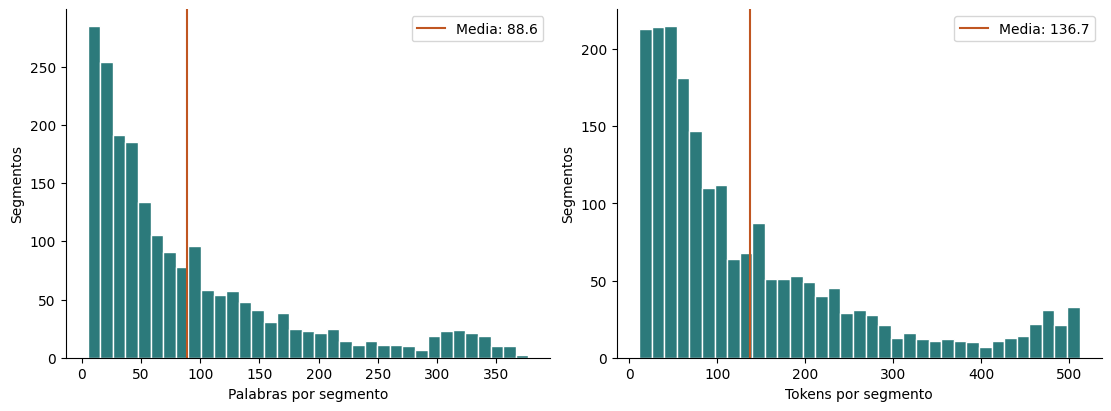

In [5]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, column, title in zip(axes, ["words", "tokens"], ["Palabras por segmento", "Tokens por segmento"]):
    ax.hist(segments[column], bins=35, color="#2c7a7b", edgecolor="white")
    ax.axvline(segments[column].mean(), color="#c05621", label=f"Media: {segments[column].mean():.1f}")
    ax.set(xlabel=title, ylabel="Segmentos")
    ax.legend()
fig.savefig(RESULTS / "longitudes.png", dpi=160)
plt.show()

La distribución es asimétrica: hay muchos diálogos breves y pocos párrafos muy largos.
El corte a 512 tokens limita la cola y evita truncamiento silencioso.
La ejecución incluida contiene **2,046 segmentos**, con **88.57 palabras** y **136.70 tokens** en promedio.
De los 1,980 párrafos originales, 75 requirieron división; se eliminaron 22 fragmentos cortos y cuatro duplicados.

## 3. Modelado: dos configuraciones

`CountVectorizer` usa las stopwords españolas de [NLTK](https://github.com/nltk/nltk_data/blob/gh-pages/packages/corpora/stopwords.zip),
incluidas en `data/stopwords_es.txt`, y algunos marcadores de diálogo y arcaísmos frecuentes.
La eliminación de stopwords solo afecta a c-TF-IDF; el encoder recibe el texto con acentos y contexto.
Se conservan los nombres de personajes para analizar su influencia.

| Parámetro | A: detalle | B: grupos amplios |
|---|---:|---:|
| `min_cluster_size` | 25 | 60 |
| `min_samples` | 5 | 10 |
| `ngram_range` | (1, 1) | (1, 2) |
| `nr_topics` | None | None |

Ambas configuraciones comparten segmentos y embeddings. UMAP usa cinco dimensiones y `random_state=42`.
Los n-gramas cambian la descripción de los tópicos; no intervienen en el clustering.
Se comparan configuraciones completas, por lo que no se aísla el efecto de cada parámetro.

Los nombres que siguen se interpretaron después del entrenamiento original. Si cambias los parámetros
 o el corpus, debes revisar esos nombres y las conclusiones.

In [6]:
embeddings = encoder.encode(
    [PREFIX + text for text in segments.text],
    batch_size=16, normalize_embeddings=True, show_progress_bar=True,
)
stopwords = sorted(set((DATA / "stopwords_es.txt").read_text().splitlines() + [
    "don", "dijo", "respondió", "replicó", "señor", "merced", "así", "pues",
    "agora", "ansí", "desta", "deste", "desto", "della", "dello", "mesmo",
]))
configs = {
    "A": {"min_cluster_size": 25, "min_samples": 5, "ngram_range": (1, 1)},
    "B": {"min_cluster_size": 60, "min_samples": 10, "ngram_range": (1, 2)},
}

Batches:   0%|          | 0/128 [00:00<?, ?it/s]

Batches:   1%|          | 1/128 [00:00<01:04,  1.97it/s]

Batches:   2%|▏         | 2/128 [00:01<01:03,  1.98it/s]

Batches:   2%|▏         | 3/128 [00:01<01:02,  2.01it/s]

Batches:   3%|▎         | 4/128 [00:01<00:59,  2.07it/s]

Batches:   4%|▍         | 5/128 [00:02<00:58,  2.12it/s]

... (70 outputs left out)

Batches:  90%|████████▉ | 115/128 [00:14<00:00, 32.30it/s]

Batches:  94%|█████████▍| 120/128 [00:15<00:00, 36.64it/s]

Batches:  98%|█████████▊| 126/128 [00:15<00:00, 42.39it/s]

Batches: 100%|██████████| 128/128 [00:15<00:00,  8.42it/s]

In [7]:
names = {'A': ['Acciones colectivas de la trama principal',
       'Transiciones del narrador hacia el diálogo',
       'Interpelaciones y réplicas sobre caballería',
       'Sancho: consejos y expectativas',
       'Imaginario y discursos caballerescos',
       'El curioso impertinente: engaño y celos',
       'El cautivo y Zoraida: rescate y fuga',
       'Fernando, Luscinda y los conflictos de honor',
       'Don Quijote responde a Sancho',
       'Réplicas breves de don Quijote',
       'Asentimientos de personajes secundarios',
       'Preguntas y asentimientos de don Quijote',
       'Dulcinea y el servicio caballeresco',
       'El cura: libros y conversaciones',
       'Fórmulas narrativas de respuesta',
       'El barbero y el escrutinio de libros'],
 'B': ['Acciones colectivas de la trama principal',
       'Transiciones del narrador hacia el diálogo',
       'Conflictos amorosos de relatos intercalados',
       'Sancho: consejos y expectativas',
       'Fórmulas breves de diálogo',
       'Don Quijote: réplicas a Sancho y otras respuestas',
       'Imaginario y discursos caballerescos',
       'Interpelaciones y réplicas sobre caballería',
       'El cautivo y Zoraida: rescate y fuga']}

In [8]:
models, tables, metrics, examples = {}, {}, [], []
for config, params in configs.items():
    model = BERTopic(
        embedding_model=encoder,
        umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                        metric="cosine", random_state=SEED, transform_seed=SEED, n_jobs=1),
        hdbscan_model=HDBSCAN(
            min_cluster_size=params["min_cluster_size"], min_samples=params["min_samples"],
            metric="euclidean", cluster_selection_method="eom",
            prediction_data=True, core_dist_n_jobs=1,
        ),
        vectorizer_model=CountVectorizer(stop_words=stopwords, ngram_range=params["ngram_range"]),
        nr_topics=None, top_n_words=10,
    )
    topics, _ = model.fit_transform(segments.text.tolist(), embeddings)
    topics = np.array(topics)
    models[config] = model
    segments[f"topic_{config}"] = topics
    info = model.get_topic_info()
    if (info.Topic != -1).sum() != len(names[config]):
        raise ValueError("Los grupos cambiaron: revisa los nombres y la interpretación.")
    info["Nombre_propio"] = [names[config][t] if t != -1 else "Sin asignación (outliers)" for t in info.Topic]
    info["Porcentaje"] = (100 * info.Count / len(segments)).round(2)
    tables[config] = info
    info.to_csv(RESULTS / f"topicos_{config}.csv", index=False)

    inliers = topics != -1
    terms = [word for t in set(topics) - {-1} for word, weight in model.get_topic(t) if word and weight > 0]
    metrics.append({
        "Configuración": config, "Tópicos": int((info.Topic != -1).sum()),
        "Outliers": int((~inliers).sum()), "Outliers (%)": round(100 * (~inliers).mean(), 2),
        "Silhouette (coseno)": silhouette_score(
            embeddings[inliers], topics[inliers], metric="cosine",
            sample_size=min(2000, int(inliers.sum())), random_state=SEED,
        ),
        "Diversidad top-10": len(set(terms)) / len(terms),
    })
    # Tres segmentos más cercanos al centroide de cada grupo, en el espacio original.
    for topic in sorted(set(topics) - {-1}):
        indices = np.flatnonzero(topics == topic)
        centroid = embeddings[indices].mean(axis=0, keepdims=True)
        similarity = cosine_similarity(embeddings[indices], centroid).ravel()
        for position in np.argsort(-similarity, kind="stable")[:3]:
            row = segments.iloc[indices[position]]
            examples.append({
                "config": config, "topic": int(topic), "name": names[config][topic],
                "segment_id": row.segment_id, "chapter": int(row.chapter),
                "text": row.text, "cosine_to_centroid": float(similarity[position]),
            })

comparison = pd.DataFrame(metrics)
examples = pd.DataFrame(examples)
segments.to_csv(RESULTS / "segmentos.csv", index=False)
examples.to_csv(RESULTS / "ejemplos.csv", index=False)
comparison.to_csv(RESULTS / "comparacion.csv", index=False)
display(comparison.round(4))

/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv

/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/blitz/Documents/TEC/Semester7/NaturalLanguage/BERT/.venv

,Configuración,Tópicos,Outliers,Outliers (%),Silhouette (coseno),Diversidad top-10
0,A,16,377,18.43,0.0539,0.6500
1,B,9,522,25.51,0.0637,0.6222


La silhouette usa distancia coseno en los embeddings originales, solo sobre inliers, con un máximo de
2,000 observaciones y semilla 42. Sus valores bajos indican separación débil, aunque haya grupos interpretables.
La diversidad es la proporción de términos distintos entre los top-10; no equivale a coherencia semántica.
A usa unigramas y B también bigramas, por lo que la comparación léxica no es completamente equivalente.

## 4. Tabla de tópicos y ejemplos

Las tablas proceden de `get_topic_info`; se añaden nombre interpretativo y porcentaje.
Los ejemplos centrales permiten explicar el grupo, pero no representan toda su diversidad interna.

In [9]:
for config, info in tables.items():
    display(Markdown(f"### Configuración {config}"))
    display(info[["Topic", "Nombre_propio", "Count", "Porcentaje", "Representation"]])

### Configuración A

,Topic,Nombre_propio,Count,Porcentaje,Representation
0,-1,Sin asignación (outliers),377,18.43,"[si, sancho, bien, quijote, tan, dios, aquí, s..."
1,0,Acciones colectivas de la trama principal,294,14.37,"[quijote, sancho, cura, dos, tan, aquel, allí,..."
2,1,Transiciones del narrador hacia el diálogo,253,12.37,"[quijote, sancho, diciendo, amo, vio, manera, ..."
3,2,Interpelaciones y réplicas sobre caballería,187,9.14,"[si, caballero, aquí, tan, vos, dios, bien, ma..."
4,3,Sancho: consejos y expectativas,182,8.90,"[sancho, si, bien, dios, sino, aquí, sé, ser, ..."
5,4,Imaginario y discursos caballerescos,139,6.79,"[caballero, si, tan, ser, caballeros, bien, ve..."
6,5,El curioso impertinente: engaño y celos,107,5.23,"[camila, lotario, anselmo, leonela, amigo, tan..."
7,6,El cautivo y Zoraida: rescate y fuga,76,3.71,"[zoraida, cristianos, renegado, padre, tierra,..."
8,7,"Fernando, Luscinda y los conflictos de honor",71,3.47,"[fernando, luscinda, padre, tan, ser, si, ciel..."
9,8,Don Quijote responde a Sancho,67,3.27,"[sancho, quijote, ahora, si, espada, caballerí..."


### Configuración B

,Topic,Nombre_propio,Count,Porcentaje,Representation
0,-1,Sin asignación (outliers),522,25.51,"[si, tan, señora, caballero, quijote, sancho, ..."
1,0,Acciones colectivas de la trama principal,294,14.37,"[quijote, sancho, cura, tan, dos, aquel, allí,..."
2,1,Transiciones del narrador hacia el diálogo,257,12.56,"[quijote, sancho, diciendo, amo, vio, manera, ..."
3,2,Conflictos amorosos de relatos intercalados,200,9.78,"[camila, lotario, anselmo, tan, si, ser, casa,..."
4,3,Sancho: consejos y expectativas,158,7.72,"[sancho, si, bien, sino, dios, ser, sé, aquí, ..."
5,4,Fórmulas breves de diálogo,152,7.43,"[quijote, barbero, preguntó, place, quijote qu..."
6,5,Don Quijote: réplicas a Sancho y otras respuestas,136,6.65,"[quijote, sancho, si, sancho quijote, ahora, h..."
7,6,Imaginario y discursos caballerescos,126,6.16,"[si, caballero, tan, ser, bien, caballeros, ve..."
8,7,Interpelaciones y réplicas sobre caballería,123,6.01,"[si, caballero, bien, aquí, tan, dios, cosa, m..."
9,8,El cautivo y Zoraida: rescate y fuga,78,3.81,"[zoraida, cristianos, renegado, padre, si, tie..."


### Valoración de cada tópico

#### Configuración A

**0. Acciones colectivas de la trama principal**

Grupo amplio de acciones del cura, Sancho y don Quijote en escenarios distintos. Los ejemplos reúnen disfraces, peleas y despojos de batalla: tiene coherencia de personajes y narración, pero no corresponde a un tema literario único. Conviene no llamarlo simplemente «aventura» como si eso explicara su diversidad.

**1. Transiciones del narrador hacia el diálogo**

Predominan introducciones a lo que los personajes van a decir, con términos como «diciendo», «voz» y «manera». Los tres ejemplos terminan anunciando un parlamento. Es una regularidad de estructura narrativa, con poco valor como tópico de contenido.

**2. Interpelaciones y réplicas sobre caballería**

Los interlocutores apelan a un caballero, comentan locuras o solicitan pruebas de una dama. La relación es el acto de dirigirse a otro con fórmulas de cortesía, más que un asunto preciso. El grupo mezcla episodios y conserva muchos conectores poco informativos.

**3. Sancho: consejos y expectativas**

Las respuestas de Sancho combinan prudencia frente a la Santa Hermandad, valoración de las locuras de su amo y expectativas de beneficio. Hay coherencia de personaje y de su perspectiva práctica. No todos los textos tratan de dinero ni de gobierno, por lo que el nombre mantiene un alcance amplio.

**4. Imaginario y discursos caballerescos**

Los ejemplos describen castillos, encantamientos, doncellas y nombres heroicos. Es uno de los grupos con una lectura temática razonable: la construcción verbal del mundo caballeresco. Reúne tanto fantasía de don Quijote como comentarios sobre su lectura, sin separarlos claramente.

**5. El curioso impertinente: engaño y celos**

Camila, Lotario, Anselmo y Leonela identifican el relato intercalado. Los ejemplos muestran ocultamiento de relaciones, sospechas y escenificación del engaño. Es un tópico reconocible, aunque detecta sobre todo un episodio y sus personajes; 103 de sus 107 segmentos están en los capítulos 33–35.

**6. El cautivo y Zoraida: rescate y fuga**

Los términos «renegado», «barca», «cristianos» y «moros» se corresponden con la negociación del rescate y la huida de Argel. Los ejemplos incluyen compra de la barca, rescate y llegada a la costa. Es coherente, pero agrupa una secuencia narrativa concreta y su representación histórica de identidades religiosas.

**7. Fernando, Luscinda y los conflictos de honor**

Los fragmentos relatan promesas, deseo, matrimonio y pérdida de reputación en torno a Fernando, Luscinda y Dorotea. La presencia de parentesco, voluntad y honor sostiene el nombre. Algunas piezas pertenecen a otros relatos amorosos: no debe tratarse como una etiqueta exacta de personajes.

**8. Don Quijote responde a Sancho**

Los tres ejemplos centrales tienen la misma situación de habla: don Quijote corrige o alienta a Sancho. La identidad de los interlocutores explica mejor el grupo que una temática única, ya que incluye aventuras, ascenso social y cordura.

**9. Réplicas breves de don Quijote**

Aparecen dolor, encantamiento y la orden de continuar una historia. «Bálsamo» figura entre los términos, pero no resume todos los ejemplos. Es una agrupación débil de tono y hablante; sería excesivo nombrarla «medicina» o «curación».

**10. Asentimientos de personajes secundarios**

Los ejemplos son «Así se hará», «Así es» y «Adelante», atribuidos a personajes diferentes. La mediana de longitud es de ocho palabras. El grupo es reconocible como fórmula de conversación, pero no como tópico literario sustantivo.

**11. Preguntas y asentimientos de don Quijote**

Los ejemplos incluyen confirmar, preguntar si se conoció a alguien y anunciar una lectura. La brevedad y el marcador de hablante dominan. La mediana de 8.5 palabras explica la escasez de contexto, y no hay un asunto compartido suficientemente específico.

**12. Dulcinea y el servicio caballeresco**

El juramento a Dulcinea y la disposición a rescatar damas ofrecen una lectura ligada al código caballeresco. Sin embargo, solo uno de los tres ejemplos centrales nombra a Dulcinea; otros tratan la investidura o la liberación de una dama. El nombre admite ese ámbito más amplio y evita atribuir todos los fragmentos a ella.

**13. El cura: libros y conversaciones**

«Libro», «libros» y «novela» sugieren el escrutinio y la lectura, pero los ejemplos también incluyen impedir una salida y ofrecer ayuda al capitán. La identidad del cura domina sobre el tema de los libros. Es útil para seguir a un personaje, poco preciso para afirmar un tema común.

**14. Fórmulas narrativas de respuesta**

Los tres ejemplos son variaciones casi idénticas de «A lo cual respondió don Quijote». Conservan más de cinco palabras y por ello pasan el filtro, pero carecen del contenido de la respuesta. Detectan un patrón estilístico; no un tópico de la novela.

**15. El barbero y el escrutinio de libros**

La mayoría relativa de segmentos se concentra en el capítulo 6 (18 de 28), donde se examinan libros. Sin embargo, los ejemplos centrales son asentimientos del barbero y del cura. El grupo combina personaje, episodio y estilo, por lo que su coherencia temática es parcial.

#### Configuración B

**0. Acciones colectivas de la trama principal**

Grupo amplio de acciones del cura, Sancho y don Quijote en escenarios distintos. Los ejemplos reúnen disfraces, peleas y despojos de batalla: tiene coherencia de personajes y narración, pero no corresponde a un tema literario único. Conviene no llamarlo simplemente «aventura» como si eso explicara su diversidad.

**1. Transiciones del narrador hacia el diálogo**

Predominan introducciones a lo que los personajes van a decir, con términos como «diciendo», «voz» y «manera». Los tres ejemplos terminan anunciando un parlamento. Es una regularidad de estructura narrativa, con poco valor como tópico de contenido.

**2. Conflictos amorosos de relatos intercalados**

Reúne todos los 107 fragmentos de A5 y los 71 de A7, además de 22 que eran outliers en A. Los términos y los tres ejemplos centrales se inclinan hacia Camila, Lotario y Anselmo, pero también incluye el conflicto de Fernando y Luscinda. Tiene coherencia general de relaciones y engaño, a costa de confundir relatos que A distinguía.

**3. Sancho: consejos y expectativas**

Las respuestas de Sancho combinan prudencia frente a la Santa Hermandad, valoración de las locuras de su amo y expectativas de beneficio. Hay coherencia de personaje y de su perspectiva práctica. No todos los textos tratan de dinero ni de gobierno, por lo que el nombre mantiene un alcance amplio.

**4. Fórmulas breves de diálogo**

Fusiona los asentimientos de secundarios, preguntas breves de don Quijote y fórmulas del narrador. Los tres ejemplos centrales contienen apenas una confirmación o introducción al habla; la mediana es de ocho palabras. Aunque el grupo es denso y grande (152 segmentos), no representa un tema literario. El bigrama «quijote quijote» surge al concatenar documentos para c-TF-IDF, no de un motivo repetido de la novela.

**5. Don Quijote: réplicas a Sancho y otras respuestas**

Reúne los 67 fragmentos de A8 y 58 de A9, además de otros segmentos. Los ejemplos centrales continúan siendo respuestas a Sancho sobre aventuras, cordura o recompensa. El agrupamiento reduce la fragmentación, pero se explica mejor por hablante y tipo de intervención que por un asunto exclusivo.

**6. Imaginario y discursos caballerescos**

Los ejemplos describen castillos, encantamientos, doncellas y nombres heroicos. Es uno de los grupos con una lectura temática razonable: la construcción verbal del mundo caballeresco. Reúne tanto fantasía de don Quijote como comentarios sobre su lectura, sin separarlos claramente.

**7. Interpelaciones y réplicas sobre caballería**

Es principalmente una versión más estricta de A2 (122 fragmentos compartidos). Los ejemplos mezclan la demanda de ver una locura, las desgracias de la caballería y la petición de un retrato. Hay un marco de habla caballeresco, pero la representación sigue siendo genérica; no basta para sostener una lectura sobre un único tema como justicia.

**8. El cautivo y Zoraida: rescate y fuga**

Los términos «renegado», «barca», «cristianos» y «moros» se corresponden con la negociación del rescate y la huida de Argel. Los ejemplos incluyen compra de la barca, rescate y llegada a la costa. Es coherente, pero agrupa una secuencia narrativa concreta y su representación histórica de identidades religiosas.

In [10]:
for config in configs:
    lines = [f"# Catálogo de tópicos · {config}"]
    for topic, name in enumerate(names[config]):
        lines += [f"## {topic}. {name}"]
        for row in examples.query("config == @config and topic == @topic").itertuples():
            lines += [f"**{row.segment_id} · capítulo {row.chapter} · coseno {row.cosine_to_centroid:.3f}**", "> " + row.text]
    # −1 no es un tópico: se muestran tres casos para inspección.
    lines += ["## −1. Sin asignación", "Se conservan; no constituyen un tema coherente."]
    outliers = segments[segments[f"topic_{config}"] == -1].copy()
    outliers["delta"] = (outliers.words - outliers.words.median()).abs()
    for row in outliers.sort_values(["delta", "segment_id"]).head(3).itertuples():
        lines += [f"**{row.segment_id} · capítulo {row.chapter}**", "> " + row.text]
    catalogue = "\n\n".join(lines)
    (RESULTS / f"catalogo_{config}.md").write_text(catalogue, encoding="utf-8")
    display(Markdown(catalogue))

# Catálogo de tópicos · A

## 0. Acciones colectivas de la trama principal

**P1-C26-S0031 · capítulo 26 · coseno 0.968**

> Sancho dijo que entrasen ellos, que él esperaría allí fuera y que después les diría la causa por que no entraba ni le convenía entrar en ella; mas que les rogaba que le sacasen allí algo de comer que fuese cosa caliente, y, ansimismo, cebada para Rocinante. Ellos se entraron y le dejaron, y, de allí a poco, el barbero le sacó de comer. Después, habiendo bien pensado entre los dos el modo que tendrían para conseguir lo que deseaban, vino el cura en un pensamiento muy acomodado al gusto de don Quijote y para lo que ellos querían. Y fue que dijo al barbero que lo que había pensado era que él se vestiría en hábito de doncella andante, y que él procurase ponerse lo mejor que pudiese como escudero, y que así irían adonde don Quijote estaba, fingiendo ser ella una doncella afligida y menesterosa, y le pediría un don, el cual él no podría dejársele de otorgar, como valeroso caballero andante. Y que el don que le pensaba pedir era que se viniese con ella donde ella le llevase, a desfacelle un agravio que un mal caballero le tenía fecho; y que le suplicaba, ansimesmo, que no la mandase quitar su antifaz, ni la demandase cosa de su facienda, fasta que la hubiese fecho derecho de aquel mal caballero; y que creyese, sin duda, que don Quijote vendría en todo cuanto le pidiese por este término; y que desta manera le sacarían de allí y le llevarían a su lugar, donde procurarían ver si tenía algún remedio su estraña locura.

**P1-C16-S0029 · capítulo 16 · coseno 0.966**

> En esto, despertó Sancho, y, sintiendo aquel bulto casi encima de sí, pensó que tenía la pesadilla, y comenzó a dar puñadas a una y otra parte, y entre otras alcanzó con no sé cuántas a Maritornes, la cual, sentida del dolor, echando a rodar la honestidad, dio el retorno a Sancho con tantas que, a su despecho, le quitó el sueño; el cual, viéndose tratar de aquella manera y sin saber de quién, alzándose como pudo, se abrazó con Maritornes, y comenzaron entre los dos la más reñida y graciosa escaramuza del mundo. Viendo, pues, el arriero, a la lumbre del candil del ventero, cuál andaba su dama, dejando a don Quijote, acudió a dalle el socorro necesario. Lo mismo hizo el ventero, pero con intención diferente, porque fue a castigar a la moza, creyendo sin duda que ella sola era la ocasión de toda aquella armonía. Y así como suele decirse: el gato al rato, el rato a la cuerda, la cuerda al palo, daba el arriero a Sancho, Sancho a la moza, la moza a él, el ventero a la moza, y todos menudeaban con tanta priesa que no se daban punto de reposo; y fue lo bueno que al ventero se le apagó el candil, y, como quedaron ascuras, dábanse tan sin compasión todos a bulto que, a doquiera que ponían la mano, no dejaban cosa sana.

**P1-C08-S0036 · capítulo 8 · coseno 0.965**

> Sancho Panza, que vio en el suelo al fraile, apeándose ligeramente de su asno, arremetió a él y le comenzó a quitar los hábitos. Llegaron en esto dos mozos de los frailes y preguntáronle que por qué le desnudaba. Respondióles Sancho que aquello le tocaba a él ligítimamente, como despojos de la batalla que su señor don Quijote había ganado. Los mozos, que no sabían de burlas, ni entendían aquello de despojos ni batallas, viendo que ya don Quijote estaba desviado de allí, hablando con las que en el coche venían, arremetieron con Sancho y dieron con él en el suelo; y, sin dejarle pelo en las barbas, le molieron a coces y le dejaron tendido en el suelo sin aliento ni sentido. Y, sin detenerse un punto, tornó a subir el fraile, todo temeroso y acobardado y sin color en el rostro; y, cuando se vio a caballo, picó tras su compañero, que un buen espacio de allí le estaba aguardando, y esperando en qué paraba aquel sobresalto; y, sin querer aguardar el fin de todo aquel comenzado suceso, siguieron su camino, haciéndose más cruces que si llevaran al diablo a las espaldas.

## 1. Transiciones del narrador hacia el diálogo

**P1-C37-S0049 · capítulo 37 · coseno 0.961**

> De tal manera, y por tan buenos términos, iba prosiguiendo en su plática don Quijote que obligó a que, por entonces, ninguno de los que escuchándole estaban le tuviese por loco; antes, como todos los más eran caballeros, a quien son anejas las armas, le escuchaban de muy buena gana; y él prosiguió diciendo:

**P1-C04-S0030 · capítulo 4 · coseno 0.960**

> Y desta manera deshizo el agravio el valeroso don Quijote; el cual, contentísimo de lo sucedido, pareciéndole que había dado felicísimo y alto principio a sus caballerías, con gran satisfación de sí mismo iba caminando hacia su aldea, diciendo a media voz:

**P1-C18-S0008 · capítulo 18 · coseno 0.960**

> Es estos coloquios iban don Quijote y su escudero, cuando vio don Quijote que por el camino que iban venía hacia ellos una grande y espesa polvareda; y, en viéndola, se volvió a Sancho y le dijo:

## 2. Interpelaciones y réplicas sobre caballería

**P1-C52-S0002 · capítulo 52 · coseno 0.955**

> — Por cierto, hermano cabrero, que si yo me hallara posibilitado de poder comenzar alguna aventura, que luego luego me pusiera en camino porque vos la tuviérades buena; que yo sacara del monesterio, donde, sin duda alguna, debe de estar contra su voluntad, a Leandra, a pesar de la abadesa y de cuantos quisieran estorbarlo, y os la pusiera en vuestras manos, para que hiciérades della a toda vuestra voluntad y talante, guardando, pero, las leyes de la caballería, que mandan que a ninguna doncella se le sea fecho desaguisado alguno; aunque yo espero en Dios Nuestro Señor que no ha de poder tanto la fuerza de un encantador malicioso, que no pueda más la de otro encantador mejor intencionado, y para entonces os prometo mi favor y ayuda, como me obliga mi profesión, que no es otra si no es favorecer a los desvalidos y menesterosos.

**P1-C25-S0073 · capítulo 25 · coseno 0.955**

> — Digo, señor, que vuestra merced ha dicho muy bien: que, para que pueda jurar sin cargo de conciencia que le he visto hacer locuras, será bien que vea siquiera una, aunque bien grande la he visto en la quedada de vuestra merced.

**P1-C04-S0038 · capítulo 4 · coseno 0.955**

> — Señor caballero —replicó el mercader—, suplico a vuestra merced, en nombre de todos estos príncipes que aquí estamos, que, porque no encarguemos nuestras conciencias confesando una cosa por nosotros jamás vista ni oída, y más siendo tan en perjuicio de las emperatrices y reinas del Alcarria y Estremadura, que vuestra merced sea servido de mostrarnos algún retrato de esa señora, aunque sea tamaño como un grano de trigo; que por el hilo se sacará el ovillo, y quedaremos con esto satisfechos y seguros, y vuestra merced quedará contento y pagado; y aun creo que estamos ya tan de su parte que, aunque su retrato nos muestre que es tuerta de un ojo y que del otro le mana bermellón y piedra azufre, con todo eso, por complacer a vuestra merced, diremos en su favor todo lo que quisiere.

## 3. Sancho: consejos y expectativas

**P1-C23-S0003 · capítulo 23 · coseno 0.964**

> — Así escarmentará vuestra merced —respondió Sancho— como yo soy turco; pero, pues dice que si me hubiera creído se hubiera escusado este daño, créame ahora y escusará otro mayor; porque le hago saber que con la Santa Hermandad no hay usar de caballerías, que no se le da a ella por cuantos caballeros andantes hay dos maravedís; y sepa que ya me parece que sus saetas me zumban por los oídos.

**P1-C25-S0065 · capítulo 25 · coseno 0.964**

> — Yo me confío de vuestra merced —respondió Sancho—. Déjeme, iré a ensillar a Rocinante, y aparéjese vuestra merced a echarme su bendición, que luego pienso partirme, sin ver las sandeces que vuestra merced ha de hacer, que yo diré que le vi hacer tantas que no quiera más.

**P1-C31-S0026 · capítulo 31 · coseno 0.963**

> — Eso está claro —respondió Sancho—, pero mire vuestra merced que la escoja hacia la marina, porque, si no me contentare la vivienda, pueda embarcar mis negros vasallos y hacer dellos lo que ya he dicho. Y vuestra merced no se cure de ir por agora a ver a mi señora Dulcinea, sino váyase a matar al gigante, y concluyamos este negocio; que por Dios que se me asienta que ha de ser de mucha honra y de mucho provecho.

## 4. Imaginario y discursos caballerescos

**P1-C17-S0009 · capítulo 17 · coseno 0.963**

> — Sea por lo que fuere —dijo don Quijote—; que más fío de tu amor y de tu cortesía; y así, has de saber que esta noche me ha sucedido una de las más estrañas aventuras que yo sabré encarecer; y, por contártela en breve, sabrás que poco ha que a mí vino la hija del señor deste castillo, que es la más apuesta y fermosa doncella que en gran parte de la tierra se puede hallar. ¿Qué te podría decir del adorno de su persona? ¿Qué de su gallardo entendimiento? ¿Qué de otras cosas ocultas, que, por guardar la fe que debo a mi señora Dulcinea del Toboso, dejaré pasar intactas y en silencio? Sólo te quiero decir que, envidioso el cielo de tanto bien como la ventura me había puesto en las manos, o quizá, y esto es lo más cierto, que, como tengo dicho, es encantado este castillo, al tiempo que yo estaba con ella en dulcísimos y amorosísimos coloquios, sin que yo la viese ni supiese por dónde venía, vino una mano pegada a algún brazo de algún descomunal gigante y asentóme una puñada en las quijadas, tal, que las tengo todas bañadas en sangre; y después me molió de tal suerte que estoy peor que ayer cuando los gallegos, que, por demasías de Rocinante, nos hicieron el agravio que sabes. Por donde conjeturo que el tesoro de la fermosura desta doncella le debe de guardar algún encantado moro, y no debe de ser para mí.

**P1-C19-S0035 · capítulo 19 · coseno 0.963**

> — No es eso —respondió don Quijote—, sino que el sabio, a cuyo cargo debe de estar el escribir la historia de mis hazañas, le habrá parecido que será bien que yo tome algún nombre apelativo, como lo tomaban todos los caballeros pasados: cuál se llamaba el de la Ardiente Espada; cuál, el del Unicornio; aquel, de las Doncellas; aquéste, el del Ave Fénix; el otro, el Caballero del Grifo; estotro, el de la Muerte; y por estos nombres e insignias eran conocidos por toda la redondez de la tierra. Y así, digo que el sabio ya dicho te habrá puesto en la lengua y en el pensamiento ahora que me llamases el Caballero de la Triste Figura, como pienso llamarme desde hoy en adelante; y, para que mejor me cuadre tal nombre, determino de hacer pintar, cuando haya lugar, en mi escudo una muy triste figura. — No hay para qué gastar tiempo y dineros en hacer esa figura —dijo Sancho—, sino lo que se ha de hacer es que vuestra merced descubra la suya y dé rostro a los que le miraren; que, sin más ni más, y sin otra imagen ni escudo, le llamarán el de la Triste Figura; y créame que le digo verdad, porque le prometo a vuestra merced, señor, y esto sea dicho en burlas, que le hace tan mala cara la hambre y la falta de las muelas, que, como ya tengo dicho, se podrá muy bien escusar la triste pintura.

**P1-C50-S0004 · capítulo 50 · coseno 0.962**

> ¿Y, después de la comida acabada y las mesas alzadas, quedarse el caballero recostado sobre la silla, y quizá mondándose los dientes, como es costumbre, entrar a deshora por la puerta de la sala otra mucho más hermosa doncella que ninguna de las primeras, y sentarse al lado del caballero, y comenzar a darle cuenta de qué castillo es aquél, y de cómo ella está encantada en él, con otras cosas que suspenden al caballero y admiran a los leyentes que van leyendo su historia? No quiero alargarme más en esto, pues dello se puede colegir que cualquiera parte que se lea, de cualquiera historia de caballero andante, ha de causar gusto y maravilla a cualquiera que la leyere. Y vuestra merced créame, y, como otra vez le he dicho, lea estos libros, y verá cómo le destierran la melancolía que tuviere, y le mejoran la condición, si acaso la tiene mala. De mí sé decir que, después que soy caballero andante, soy valiente, comedido, liberal, bien criado, generoso, cortés, atrevido, blando, paciente, sufridor de trabajos, de prisiones, de encantos; y, aunque ha tan poco que me vi encerrado en una jaula, como loco, pienso, por el valor de mi brazo, favoreciéndome el cielo y no me siendo contraria la fortuna, en pocos días verme rey de algún reino, adonde pueda mostrar el agradecimiento y liberalidad que mi pecho encierra. Que, mía fe, señor, el pobre está inhabilitado de poder mostrar la virtud de liberalidad con ninguno, aunque en sumo grado la posea; y el agradecimiento que sólo consiste en el deseo es cosa muerta, como es muerta la fe sin obras. Por esto querría que la fortuna me ofreciese presto alguna ocasión donde me hiciese emperador, por mostrar mi pecho haciendo bien a mis amigos, especialmente a este pobre de Sancho Panza, mi escudero, que es el mejor hombre del mundo, y querría darle un condado que le tengo muchos días ha prometido, sino que temo que no ha de tener habilidad para gobernar su estado.

## 5. El curioso impertinente: engaño y celos

**P1-C34-S0009 · capítulo 34 · coseno 0.973**

> »Quedaron deste acuerdo el impertinente y el traidor amigo; y, vuelto Anselmo a su casa, preguntó a Camila lo que ella ya se maravillaba que no se lo hubiese preguntado: que fue que le dijese la ocasión por que le había escrito el papel que le envió. Camila le respondió que le había parecido que Lotario la miraba un poco más desenvueltamente que cuando él estaba en casa; pero que ya estaba desengañada y creía que había sido imaginación suya, porque ya Lotario huía de vella y de estar con ella a solas. Díjole Anselmo que bien podía estar segura de aquella sospecha, porque él sabía que Lotario andaba enamorado de una doncella principal de la ciudad, a quien él celebraba debajo del nombre de Clori, y que, aunque no lo estuviera, no había que temer de la verdad de Lotario y de la mucha amistad de entrambos. Y, a no estar avisada Camila de Lotario de que eran fingidos aquellos amores de Clori, y que él se lo había dicho a Anselmo por poder ocuparse algunos ratos en las mismas alabanzas de Camila, ella, sin duda, cayera en la desesperada red de los celos; mas, por estar ya advertida, pasó aquel sobresalto sin pesadumbre.

**P1-C34-S0036 · capítulo 34 · coseno 0.972**

> »Espantada quedó Camila de oír lo que Lotario le decía, y con mucho enojo y muchas y discretas razones le riñó y afeó su mal pensamiento y la simple y mala determinación que había tenido. Pero, como naturalmente tiene la mujer ingenio presto para el bien y para el mal más que el varón, puesto que le va faltando cuando de propósito se pone a hacer discursos, luego al instante halló Camila el modo de remediar tan al parecer inremediable negocio, y dijo a Lotario que procurase que otro día se escondiese Anselmo donde decía, porque ella pensaba sacar de su escondimiento comodidad para que desde allí en adelante los dos se gozasen sin sobresalto alguno; y, sin declararle del todo su pensamiento, le advirtió que tuviese cuidado que, en estando Anselmo escondido, él viniese cuando Leonela le llamase, y que a cuanto ella le dijese le respondiese como respondiera aunque no supiera que Anselmo le escuchaba. Porfió Lotario que le acabase de declarar su intención, porque con más seguridad y aviso guardase todo lo que viese ser necesario.

**P1-C34-S0029 · capítulo 34 · coseno 0.971**

> »Pero no los pudo quitar que Lotario no le viese una vez salir, al romper del alba; el cual, sin conocer quién era, pensó primero que debía de ser alguna fantasma; mas, cuando le vio caminar, embozarse y encubrirse con cuidado y recato, cayó de su simple pensamiento y dio en otro, que fuera la perdición de todos si Camila no lo remediara. Pensó Lotario que aquel hombre que había visto salir tan a deshora de casa de Anselmo no había entrado en ella por Leonela, ni aun se acordó si Leonela era en el mundo; sólo creyó que Camila, de la misma manera que había sido fácil y ligera con él, lo era para otro; que estas añadiduras trae consigo la maldad de la mujer mala: que pierde el crédito de su honra con el mesmo a quien se entregó rogada y persuadida, y cree que con mayor facilidad se entrega a otros, y da infalible crédito a cualquiera sospecha que desto le venga. Y no parece sino que le faltó a Lotario en este punto todo su buen entendimiento, y se le fueron de la memoria todos sus advertidos discursos, pues, sin hacer alguno que bueno fuese, ni aun razonable, sin más ni más, antes que Anselmo se levantase, impaciente y ciego de la celosa rabia que las entrañas le roía, muriendo por vengarse de Camila, que en ninguna cosa le había ofendido, se fue a Anselmo y le dijo:

## 6. El cautivo y Zoraida: rescate y fuga

**P1-C40-S0029 · capítulo 40 · coseno 0.968**

> »Y, puesto que a mí y a mis camaradas nos había parecido mejor lo de enviar por la barca a Mallorca, como la mora decía, no osamos contradecirle, temerosos que, si no hacíamos lo que él decía, nos había de descubrir y poner a peligro de perder las vidas, si descubriese el trato de Zoraida, por cuya vida diéramos todos las nuestras. Y así, determinamos de ponernos en las manos de Dios y en las del renegado, y en aquel mismo punto se le respondió a Zoraida, diciéndole que haríamos todo cuanto nos aconsejaba, porque lo había advertido tan bien como si Lela Marién se lo hubiera dicho, y que en ella sola estaba dilatar aquel negocio, o ponello luego por obra. Ofrecímele de nuevo de ser su esposo, y, con esto, otro día que acaeció a estar solo el baño, en diversas veces, con la caña y el paño, nos dio dos mil escudos de oro, y un papel donde decía que el primer jumá, que es el viernes, se iba al jardín de su padre, y que antes que se fuese nos daría más dinero, y que si aquello no bastase, que se lo avisásemos, que nos daría cuanto le pidiésemos: que su padre tenía tantos, que no lo echaría menos, cuanto más, que ella tenía la llaves de todo.

**P1-C40-S0030 · capítulo 40 · coseno 0.968**

> »Dimos luego quinientos escudos al renegado para comprar la barca; con ochocientos me rescaté yo, dando el dinero a un mercader valenciano que a la sazón se hallaba en Argel, el cual me rescató del rey, tomándome sobre su palabra, dándola de que con el primer bajel que viniese de Valencia pagaría mi rescate; porque si luego diera el dinero, fuera dar sospechas al rey que había muchos días que mi rescate estaba en Argel, y que el mercader, por sus granjerías, lo había callado. Finalmente, mi amo era tan caviloso que en ninguna manera me atreví a que luego se desembolsase el dinero. El jueves antes del viernes que la hermosa Zoraida se había de ir al jardín, nos dio otros mil escudos y nos avisó de su partida, rogándome que, si me rescatase, supiese luego el jardín de su padre, y que en todo caso buscase ocasión de ir allá y verla. Respondíle en breves palabras que así lo haría, y que tuviese cuidado de encomendarnos a Lela Marién, con todas aquellas oraciones que la cautiva le había enseñado.

**P1-C41-S0033 · capítulo 41 · coseno 0.966**

> »Luego que los jinetes entendieron que éramos cristianos cautivos, se apearon de sus caballos, y cada uno nos convidaba con el suyo para llevarnos a la ciudad de Vélez Málaga, que legua y media de allí estaba. Algunos dellos volvieron a llevar la barca a la ciudad, diciéndoles dónde la habíamos dejado; otros nos subieron a las ancas, y Zoraida fue en las del caballo del tío del cristiano. Saliónos a recebir todo el pueblo, que ya de alguno que se había adelantado sabían la nueva de nuestra venida. No se admiraban de ver cautivos libres, ni moros cautivos, porque toda la gente de aquella costa está hecha a ver a los unos y a los otros; pero admirábanse de la hermosura de Zoraida, la cual en aquel instante y sazón estaba en su punto, ansí con el cansancio del camino como con la alegría de verse ya en tierra de cristianos, sin sobresalto de perderse; y esto le había sacado al rostro tales colores que, si no es que la afición entonces me engañaba, osaré decir que más hermosa criatura no había en el mundo; a lo menos, que yo la hubiese visto.

## 7. Fernando, Luscinda y los conflictos de honor

**P1-C24-S0017 · capítulo 24 · coseno 0.969**

> »Sucedió, pues, que, como el amor en los mozos, por la mayor parte, no lo es, sino apetito, el cual, como tiene por último fin el deleite, en llegando a alcanzarle se acaba y ha de volver atrás aquello que parecía amor, porque no puede pasar adelante del término que le puso naturaleza, el cual término no le puso a lo que es verdadero amor...; quiero decir que, así como don Fernando gozó a la labradora, se le aplacaron sus deseos y se resfriaron sus ahíncos; y si primero fingía quererse ausentar, por remediarlos, ahora de veras procuraba irse, por no ponerlos en ejecución. Diole el duque licencia, y mandóme que le acompañase. Venimos a mi ciudad, recibióle mi padre como quien era; vi yo luego a Luscinda, tornaron a vivir, aunque no habían estado muertos ni amortiguados, mis deseos, de los cuales di cuenta, por mi mal, a don Fernando, por parecerme que, en la ley de la mucha amistad que mostraba, no le debía encubrir nada. Alabéle la hermosura, donaire y discreción de Luscinda de tal manera, que mis alabanzas movieron en él los deseos de querer ver doncella de tantas buenas partes adornada. Cumplíselos yo, por mi corta suerte, enseñándosela una noche, a la luz de una vela, por una ventana por donde los dos solíamos hablarnos. Viola en sayo, tal, que todas las bellezas hasta entonces por él vistas las puso en olvido. Enmudeció, perdió el sentido, quedó absorto y, finalmente, tan enamorado cual lo veréis en el discurso del cuento de mi desventura. Y, para encenderle más el deseo, que a mí me celaba y al cielo a solas descubría, quiso la fortuna que hallase un día un billete suyo pidiéndome que la pidiese a su padre por esposa, tan discreto, tan honesto y tan enamorado que, en leyéndolo, me dijo que en sola Luscinda se encerraban todas las gracias de hermosura y de entendimiento que en las demás mujeres del mundo estaban repartidas.

**P1-C27-S0018 · capítulo 27 · coseno 0.965**

> Cada día descubro en vos valores que me obligan y fuerzan a que en más os estime; y así, si quisiéredes sacarme desta deuda sin ejecutarme en la honra, lo podréis muy bien hacer. Padre tengo, que os conoce y que me quiere bien, el cual, sin forzar mi voluntad, cumplirá la que será justo que vos tengáis, si es que me estimáis como decís y como yo creo. — »Por este billete me moví a pedir a Luscinda por esposa, como ya os he contado, y éste fue por quien quedó Luscinda en la opinión de don Fernando por una de las más discretas y avisadas mujeres de su tiempo; y este billete fue el que le puso en deseo de destruirme, antes que el mío se efetuase. Díjele yo a don Fernando en lo que reparaba el padre de Luscinda, que era en que mi padre se la pidiese, lo cual yo no le osaba decir, temeroso que no vendría en ello, no porque no tuviese bien conocida la calidad, bondad, virtud y hermosura de Luscinda, y que tenía partes bastantes para enoblecer cualquier otro linaje de España, sino porque yo entendía dél que deseaba que no me casase tan presto, hasta ver lo que el duque Ricardo hacía conmigo. En resolución, le dije que no me aventuraba a decírselo a mi padre, así por aquel inconveniente como por otros muchos que me acobardaban, sin saber cuáles eran, sino que me parecía que lo que yo desease jamás había de tener efeto.

**P1-C28-S0029 · capítulo 28 · coseno 0.964**

> »Estando, pues, en la ciudad, sin saber qué hacerme, pues a don Fernando no hallaba, llegó a mis oídos un público pregón, donde se prometía grande hallazgo a quien me hallase, dando las señas de la edad y del mesmo traje que traía; y oí decir que se decía que me había sacado de casa de mis padres el mozo que conmigo vino, cosa que me llegó al alma, por ver cuán de caída andaba mi crédito, pues no bastaba perderle con mi venida, sino añadir el con quién, siendo subjeto tan bajo y tan indigno de mis buenos pensamientos. Al punto que oí el pregón, me salí de la ciudad con mi criado, que ya comenzaba a dar muestras de titubear en la fe que de fidelidad me tenía prometida, y aquella noche nos entramos por lo espeso desta montaña, con el miedo de no ser hallados. Pero, como suele decirse que un mal llama a otro, y que el fin de una desgracia suele ser principio de otra mayor, así me sucedió a mí, porque mi buen criado, hasta entonces fiel y seguro, así como me vio en esta soledad, incitado de su mesma bellaquería antes que de mi hermosura, quiso aprovecharse de la ocasión que, a su parecer, estos yermos le ofrecían; y, con poca vergüenza y menos temor de Dios ni respeto mío, me requirió de amores; y, viendo que yo con feas y justas palabras respondía a las desvergüenzas de sus propósitos, dejó aparte los ruegos, de quien primero pensó aprovecharse, y comenzó a usar de la fuerza. Pero el justo cielo, que pocas o ningunas veces deja de mirar y favorecer a las justas intenciones, favoreció las mías, de manera que con mis pocas fuerzas, y con poco trabajo, di con él por un derrumbadero, donde le dejé, ni sé si muerto o si vivo;

## 8. Don Quijote responde a Sancho

**P1-C08-S0029 · capítulo 8 · coseno 0.968**

> — Ya te he dicho, Sancho —respondió don Quijote—, que sabes poco de achaque de aventuras; lo que yo digo es verdad, y ahora lo verás.

**P1-C07-S0030 · capítulo 7 · coseno 0.965**

> — Encomiéndalo tú a Dios, Sancho —respondió don Quijote—, que Él dará lo que más le convenga, pero no apoques tu ánimo tanto, que te vengas a contentar con menos que con ser adelantado.

**P1-C25-S0068 · capítulo 25 · coseno 0.964**

> — A fe, Sancho —dijo don Quijote—, que, a lo que parece, que no estás tú más cuerdo que yo.

## 9. Réplicas breves de don Quijote

**P1-C08-S0018 · capítulo 8 · coseno 0.962**

> — Así es la verdad —respondió don Quijote—; y si no me quejo del dolor, es porque no es dado a los caballeros andantes quejarse de herida alguna, aunque se le salgan las tripas por ella.

**P1-C37-S0008 · capítulo 37 · coseno 0.961**

> — No me maravillaría de nada deso —replicó don Quijote—, porque, si bien te acuerdas, la otra vez que aquí estuvimos te dije yo que todo cuanto aquí sucedía eran cosas de encantamento, y no sería mucho que ahora fuese lo mesmo.

**P1-C20-S0020 · capítulo 20 · coseno 0.959**

> — Di como quisieres —respondió don Quijote—; que, pues la suerte quiere que no pueda dejar de escucharte, prosigue.

## 10. Asentimientos de personajes secundarios

**P1-C44-S0006 · capítulo 44 · coseno 0.944**

> — Así se hará —respondió uno dellos.

**P1-C49-S0020 · capítulo 49 · coseno 0.944**

> — Así es —dijo el canónigo.

**P1-C06-S0012 · capítulo 6 · coseno 0.942**

> — Adelante —dijo el cura.

## 11. Preguntas y asentimientos de don Quijote

**P1-C21-S0053 · capítulo 21 · coseno 0.972**

> — Así será —respondió don Quijote.

**P1-C20-S0022 · capítulo 20 · coseno 0.968**

> — Luego, ¿conocístela tú? —dijo don Quijote.

**P1-C25-S0052 · capítulo 25 · coseno 0.967**

> — Escucha, que así dice —dijo don Quijote:

## 12. Dulcinea y el servicio caballeresco

**P1-C08-S0038 · capítulo 8 · coseno 0.966**

> — La vuestra fermosura, señora mía, puede facer de su persona lo que más le viniere en talante, porque ya la soberbia de vuestros robadores yace por el suelo, derribada por este mi fuerte brazo; y, porque no penéis por saber el nombre de vuestro libertador, sabed que yo me llamo don Quijote de la Mancha, caballero andante y aventurero, y cautivo de la sin par y hermosa doña Dulcinea del Toboso; y, en pago del beneficio que de mí habéis recebido, no quiero otra cosa sino que volváis al Toboso, y que de mi parte os presentéis ante esta señora y le digáis lo que por vuestra libertad he fecho.

**P1-C03-S0004 · capítulo 3 · coseno 0.963**

> — No esperaba yo menos de la gran magnificencia vuestra, señor mío — respondió don Quijote—; y así, os digo que el don que os he pedido, y de vuestra liberalidad me ha sido otorgado, es que mañana en aquel día me habéis de armar caballero, y esta noche en la capilla deste vuestro castillo velaré las armas; y mañana, como tengo dicho, se cumplirá lo que tanto deseo, para poder, como se debe, ir por todas las cuatro partes del mundo buscando las aventuras, en pro de los menesterosos, como está a cargo de la caballería y de los caballeros andantes, como yo soy, cuyo deseo a semejantes fazañas es inclinado.

**P1-C52-S0022 · capítulo 52 · coseno 0.961**

> — En una lo diré —replicó don Quijote—, y es ésta: que luego al punto dejéis libre a esa hermosa señora, cuyas lágrimas y triste semblante dan claras muestras que la lleváis contra su voluntad y que algún notorio desaguisado le habedes fecho; y yo, que nací en el mundo para desfacer semejantes agravios, no consentiré que un solo paso adelante pase sin darle la deseada libertad que merece.

## 13. El cura: libros y conversaciones

**P1-C46-S0002 · capítulo 46 · coseno 0.962**

> — Con todo eso —dijo el cura—, por esta vez no le habéis de llevar, ni aun él dejará llevarse, a lo que yo entiendo.

**P1-C32-S0043 · capítulo 32 · coseno 0.957**

> — Pues desa manera —dijo el cura—, quiero leerla, por curiosidad siquiera; quizá tendrá alguna de gusto.

**P1-C42-S0014 · capítulo 42 · coseno 0.951**

> — Déjeseme a mí el hacer esa experiencia —dijo el cura—; cuanto más, que no hay pensar sino que vos, señor capitán, seréis muy bien recebido; porque el valor y prudencia que en su buen parecer descubre vuestro hermano no da indicios de ser arrogante ni desconocido, ni que no ha de saber poner los casos de la fortuna en su punto.

## 14. Fórmulas narrativas de respuesta

**P1-C50-S0011 · capítulo 50 · coseno 0.974**

> A lo cual replicó don Quijote:

**P1-C07-S0025 · capítulo 7 · coseno 0.973**

> A lo cual le respondió don Quijote:

**P1-C10-S0003 · capítulo 10 · coseno 0.970**

> A lo cual respondió don Quijote:

## 15. El barbero y el escrutinio de libros

**P1-C06-S0038 · capítulo 6 · coseno 0.961**

> — Que me place —respondió el barbero.

**P1-C29-S0038 · capítulo 29 · coseno 0.957**

> — Así es —respondió el barbero.

**P1-C45-S0006 · capítulo 45 · coseno 0.949**

> — Así es —dijo el cura, que ya había entendido la intención de su amigo el barbero.

## −1. Sin asignación

Se conservan; no constituyen un tema coherente.

**P1-C12-S0021 · capítulo 12**

> — Perdonad, amigo —dijo don Quijote—; que por haber tanta diferencia de sarna a Sarra os lo dije; pero vos respondistes muy bien, porque vive más sarna que Sarra; y proseguid vuestra historia, que no os replicaré más en nada.

**P1-C13-S0029 · capítulo 13**

> — Aunque el mío es de los Cachopines de Laredo —respondió el caminante—, no le osaré yo poner con el del Toboso de la Mancha, puesto que, para decir verdad, semejante apellido hasta ahora no ha llegado a mis oídos.

**P1-C19-S0032 · capítulo 19**

> — Si acaso quisieren saber esos señores quién ha sido el valeroso que tales los puso, diráles vuestra merced que es el famoso don Quijote de la Mancha, que por otro nombre se llama el Caballero de la Triste Figura.

# Catálogo de tópicos · B

## 0. Acciones colectivas de la trama principal

**P1-C26-S0031 · capítulo 26 · coseno 0.968**

> Sancho dijo que entrasen ellos, que él esperaría allí fuera y que después les diría la causa por que no entraba ni le convenía entrar en ella; mas que les rogaba que le sacasen allí algo de comer que fuese cosa caliente, y, ansimismo, cebada para Rocinante. Ellos se entraron y le dejaron, y, de allí a poco, el barbero le sacó de comer. Después, habiendo bien pensado entre los dos el modo que tendrían para conseguir lo que deseaban, vino el cura en un pensamiento muy acomodado al gusto de don Quijote y para lo que ellos querían. Y fue que dijo al barbero que lo que había pensado era que él se vestiría en hábito de doncella andante, y que él procurase ponerse lo mejor que pudiese como escudero, y que así irían adonde don Quijote estaba, fingiendo ser ella una doncella afligida y menesterosa, y le pediría un don, el cual él no podría dejársele de otorgar, como valeroso caballero andante. Y que el don que le pensaba pedir era que se viniese con ella donde ella le llevase, a desfacelle un agravio que un mal caballero le tenía fecho; y que le suplicaba, ansimesmo, que no la mandase quitar su antifaz, ni la demandase cosa de su facienda, fasta que la hubiese fecho derecho de aquel mal caballero; y que creyese, sin duda, que don Quijote vendría en todo cuanto le pidiese por este término; y que desta manera le sacarían de allí y le llevarían a su lugar, donde procurarían ver si tenía algún remedio su estraña locura.

**P1-C16-S0029 · capítulo 16 · coseno 0.966**

> En esto, despertó Sancho, y, sintiendo aquel bulto casi encima de sí, pensó que tenía la pesadilla, y comenzó a dar puñadas a una y otra parte, y entre otras alcanzó con no sé cuántas a Maritornes, la cual, sentida del dolor, echando a rodar la honestidad, dio el retorno a Sancho con tantas que, a su despecho, le quitó el sueño; el cual, viéndose tratar de aquella manera y sin saber de quién, alzándose como pudo, se abrazó con Maritornes, y comenzaron entre los dos la más reñida y graciosa escaramuza del mundo. Viendo, pues, el arriero, a la lumbre del candil del ventero, cuál andaba su dama, dejando a don Quijote, acudió a dalle el socorro necesario. Lo mismo hizo el ventero, pero con intención diferente, porque fue a castigar a la moza, creyendo sin duda que ella sola era la ocasión de toda aquella armonía. Y así como suele decirse: el gato al rato, el rato a la cuerda, la cuerda al palo, daba el arriero a Sancho, Sancho a la moza, la moza a él, el ventero a la moza, y todos menudeaban con tanta priesa que no se daban punto de reposo; y fue lo bueno que al ventero se le apagó el candil, y, como quedaron ascuras, dábanse tan sin compasión todos a bulto que, a doquiera que ponían la mano, no dejaban cosa sana.

**P1-C08-S0036 · capítulo 8 · coseno 0.965**

> Sancho Panza, que vio en el suelo al fraile, apeándose ligeramente de su asno, arremetió a él y le comenzó a quitar los hábitos. Llegaron en esto dos mozos de los frailes y preguntáronle que por qué le desnudaba. Respondióles Sancho que aquello le tocaba a él ligítimamente, como despojos de la batalla que su señor don Quijote había ganado. Los mozos, que no sabían de burlas, ni entendían aquello de despojos ni batallas, viendo que ya don Quijote estaba desviado de allí, hablando con las que en el coche venían, arremetieron con Sancho y dieron con él en el suelo; y, sin dejarle pelo en las barbas, le molieron a coces y le dejaron tendido en el suelo sin aliento ni sentido. Y, sin detenerse un punto, tornó a subir el fraile, todo temeroso y acobardado y sin color en el rostro; y, cuando se vio a caballo, picó tras su compañero, que un buen espacio de allí le estaba aguardando, y esperando en qué paraba aquel sobresalto; y, sin querer aguardar el fin de todo aquel comenzado suceso, siguieron su camino, haciéndose más cruces que si llevaran al diablo a las espaldas.

## 1. Transiciones del narrador hacia el diálogo

**P1-C37-S0049 · capítulo 37 · coseno 0.961**

> De tal manera, y por tan buenos términos, iba prosiguiendo en su plática don Quijote que obligó a que, por entonces, ninguno de los que escuchándole estaban le tuviese por loco; antes, como todos los más eran caballeros, a quien son anejas las armas, le escuchaban de muy buena gana; y él prosiguió diciendo:

**P1-C04-S0030 · capítulo 4 · coseno 0.960**

> Y desta manera deshizo el agravio el valeroso don Quijote; el cual, contentísimo de lo sucedido, pareciéndole que había dado felicísimo y alto principio a sus caballerías, con gran satisfación de sí mismo iba caminando hacia su aldea, diciendo a media voz:

**P1-C18-S0008 · capítulo 18 · coseno 0.960**

> Es estos coloquios iban don Quijote y su escudero, cuando vio don Quijote que por el camino que iban venía hacia ellos una grande y espesa polvareda; y, en viéndola, se volvió a Sancho y le dijo:

## 2. Conflictos amorosos de relatos intercalados

**P1-C34-S0009 · capítulo 34 · coseno 0.966**

> »Quedaron deste acuerdo el impertinente y el traidor amigo; y, vuelto Anselmo a su casa, preguntó a Camila lo que ella ya se maravillaba que no se lo hubiese preguntado: que fue que le dijese la ocasión por que le había escrito el papel que le envió. Camila le respondió que le había parecido que Lotario la miraba un poco más desenvueltamente que cuando él estaba en casa; pero que ya estaba desengañada y creía que había sido imaginación suya, porque ya Lotario huía de vella y de estar con ella a solas. Díjole Anselmo que bien podía estar segura de aquella sospecha, porque él sabía que Lotario andaba enamorado de una doncella principal de la ciudad, a quien él celebraba debajo del nombre de Clori, y que, aunque no lo estuviera, no había que temer de la verdad de Lotario y de la mucha amistad de entrambos. Y, a no estar avisada Camila de Lotario de que eran fingidos aquellos amores de Clori, y que él se lo había dicho a Anselmo por poder ocuparse algunos ratos en las mismas alabanzas de Camila, ella, sin duda, cayera en la desesperada red de los celos; mas, por estar ya advertida, pasó aquel sobresalto sin pesadumbre.

**P1-C34-S0029 · capítulo 34 · coseno 0.966**

> »Pero no los pudo quitar que Lotario no le viese una vez salir, al romper del alba; el cual, sin conocer quién era, pensó primero que debía de ser alguna fantasma; mas, cuando le vio caminar, embozarse y encubrirse con cuidado y recato, cayó de su simple pensamiento y dio en otro, que fuera la perdición de todos si Camila no lo remediara. Pensó Lotario que aquel hombre que había visto salir tan a deshora de casa de Anselmo no había entrado en ella por Leonela, ni aun se acordó si Leonela era en el mundo; sólo creyó que Camila, de la misma manera que había sido fácil y ligera con él, lo era para otro; que estas añadiduras trae consigo la maldad de la mujer mala: que pierde el crédito de su honra con el mesmo a quien se entregó rogada y persuadida, y cree que con mayor facilidad se entrega a otros, y da infalible crédito a cualquiera sospecha que desto le venga. Y no parece sino que le faltó a Lotario en este punto todo su buen entendimiento, y se le fueron de la memoria todos sus advertidos discursos, pues, sin hacer alguno que bueno fuese, ni aun razonable, sin más ni más, antes que Anselmo se levantase, impaciente y ciego de la celosa rabia que las entrañas le roía, muriendo por vengarse de Camila, que en ninguna cosa le había ofendido, se fue a Anselmo y le dijo:

**P1-C34-S0064 · capítulo 34 · coseno 0.965**

> »—No tengas pena, señora: de aquí a mañana —respondió Leonela— yo pensaré qué le digamos, y quizá que, por ser la herida donde es, la podrás encubrir sin que él la vea, y el cielo será servido de favorecer a nuestros tan justos y tan honrados pensamientos. Sosiégate, señora mía, y procura sosegar tu alteración, porque mi señor no te halle sobresaltada, y lo demás déjalo a mi cargo, y al de Dios, que siempre acude a los buenos deseos. »Atentísimo había estado Anselmo a escuchar y a ver representar la tragedia de la muerte de su honra; la cual con tan estraños y eficaces afectos la representaron los personajes della, que pareció que se habían transformado en la misma verdad de lo que fingían. Deseaba mucho la noche, y el tener lugar para salir de su casa, y ir a verse con su buen amigo Lotario, congratulándose con él de la margarita preciosa que había hallado en el desengaño de la bondad de su esposa. Tuvieron cuidado las dos de darle lugar y comodidad a que saliese, y él, sin perdella, salió y luego fue a buscar a Lotario, el cual hallado, no se puede buenamente contar los abrazos que le dio, las cosas que de su contento le dijo, las alabanzas que dio a Camila. Todo lo cual escuchó Lotario sin poder dar muestras de alguna alegría, porque se le representaba a la memoria cuán engañado estaba su amigo y cuán injustamente él le agraviaba. Y, aunque Anselmo veía que Lotario no se alegraba, creía ser la causa por haber dejado a Camila herida y haber él sido la causa; y así, entre otras razones, le dijo que no tuviese pena del suceso de Camila, porque, sin duda, la herida era ligera, pues quedaban de concierto de encubrírsela a él;

## 3. Sancho: consejos y expectativas

**P1-C23-S0003 · capítulo 23 · coseno 0.964**

> — Así escarmentará vuestra merced —respondió Sancho— como yo soy turco; pero, pues dice que si me hubiera creído se hubiera escusado este daño, créame ahora y escusará otro mayor; porque le hago saber que con la Santa Hermandad no hay usar de caballerías, que no se le da a ella por cuantos caballeros andantes hay dos maravedís; y sepa que ya me parece que sus saetas me zumban por los oídos.

**P1-C25-S0065 · capítulo 25 · coseno 0.964**

> — Yo me confío de vuestra merced —respondió Sancho—. Déjeme, iré a ensillar a Rocinante, y aparéjese vuestra merced a echarme su bendición, que luego pienso partirme, sin ver las sandeces que vuestra merced ha de hacer, que yo diré que le vi hacer tantas que no quiera más.

**P1-C31-S0026 · capítulo 31 · coseno 0.963**

> — Eso está claro —respondió Sancho—, pero mire vuestra merced que la escoja hacia la marina, porque, si no me contentare la vivienda, pueda embarcar mis negros vasallos y hacer dellos lo que ya he dicho. Y vuestra merced no se cure de ir por agora a ver a mi señora Dulcinea, sino váyase a matar al gigante, y concluyamos este negocio; que por Dios que se me asienta que ha de ser de mucha honra y de mucho provecho.

## 4. Fórmulas breves de diálogo

**P1-C21-S0053 · capítulo 21 · coseno 0.960**

> — Así será —respondió don Quijote.

**P1-C25-S0052 · capítulo 25 · coseno 0.958**

> — Escucha, que así dice —dijo don Quijote:

**P1-C50-S0011 · capítulo 50 · coseno 0.956**

> A lo cual replicó don Quijote:

## 5. Don Quijote: réplicas a Sancho y otras respuestas

**P1-C08-S0029 · capítulo 8 · coseno 0.965**

> — Ya te he dicho, Sancho —respondió don Quijote—, que sabes poco de achaque de aventuras; lo que yo digo es verdad, y ahora lo verás.

**P1-C25-S0068 · capítulo 25 · coseno 0.961**

> — A fe, Sancho —dijo don Quijote—, que, a lo que parece, que no estás tú más cuerdo que yo.

**P1-C07-S0030 · capítulo 7 · coseno 0.961**

> — Encomiéndalo tú a Dios, Sancho —respondió don Quijote—, que Él dará lo que más le convenga, pero no apoques tu ánimo tanto, que te vengas a contentar con menos que con ser adelantado.

## 6. Imaginario y discursos caballerescos

**P1-C50-S0004 · capítulo 50 · coseno 0.963**

> ¿Y, después de la comida acabada y las mesas alzadas, quedarse el caballero recostado sobre la silla, y quizá mondándose los dientes, como es costumbre, entrar a deshora por la puerta de la sala otra mucho más hermosa doncella que ninguna de las primeras, y sentarse al lado del caballero, y comenzar a darle cuenta de qué castillo es aquél, y de cómo ella está encantada en él, con otras cosas que suspenden al caballero y admiran a los leyentes que van leyendo su historia? No quiero alargarme más en esto, pues dello se puede colegir que cualquiera parte que se lea, de cualquiera historia de caballero andante, ha de causar gusto y maravilla a cualquiera que la leyere. Y vuestra merced créame, y, como otra vez le he dicho, lea estos libros, y verá cómo le destierran la melancolía que tuviere, y le mejoran la condición, si acaso la tiene mala. De mí sé decir que, después que soy caballero andante, soy valiente, comedido, liberal, bien criado, generoso, cortés, atrevido, blando, paciente, sufridor de trabajos, de prisiones, de encantos; y, aunque ha tan poco que me vi encerrado en una jaula, como loco, pienso, por el valor de mi brazo, favoreciéndome el cielo y no me siendo contraria la fortuna, en pocos días verme rey de algún reino, adonde pueda mostrar el agradecimiento y liberalidad que mi pecho encierra. Que, mía fe, señor, el pobre está inhabilitado de poder mostrar la virtud de liberalidad con ninguno, aunque en sumo grado la posea; y el agradecimiento que sólo consiste en el deseo es cosa muerta, como es muerta la fe sin obras. Por esto querría que la fortuna me ofreciese presto alguna ocasión donde me hiciese emperador, por mostrar mi pecho haciendo bien a mis amigos, especialmente a este pobre de Sancho Panza, mi escudero, que es el mejor hombre del mundo, y querría darle un condado que le tengo muchos días ha prometido, sino que temo que no ha de tener habilidad para gobernar su estado.

**P1-C17-S0009 · capítulo 17 · coseno 0.963**

> — Sea por lo que fuere —dijo don Quijote—; que más fío de tu amor y de tu cortesía; y así, has de saber que esta noche me ha sucedido una de las más estrañas aventuras que yo sabré encarecer; y, por contártela en breve, sabrás que poco ha que a mí vino la hija del señor deste castillo, que es la más apuesta y fermosa doncella que en gran parte de la tierra se puede hallar. ¿Qué te podría decir del adorno de su persona? ¿Qué de su gallardo entendimiento? ¿Qué de otras cosas ocultas, que, por guardar la fe que debo a mi señora Dulcinea del Toboso, dejaré pasar intactas y en silencio? Sólo te quiero decir que, envidioso el cielo de tanto bien como la ventura me había puesto en las manos, o quizá, y esto es lo más cierto, que, como tengo dicho, es encantado este castillo, al tiempo que yo estaba con ella en dulcísimos y amorosísimos coloquios, sin que yo la viese ni supiese por dónde venía, vino una mano pegada a algún brazo de algún descomunal gigante y asentóme una puñada en las quijadas, tal, que las tengo todas bañadas en sangre; y después me molió de tal suerte que estoy peor que ayer cuando los gallegos, que, por demasías de Rocinante, nos hicieron el agravio que sabes. Por donde conjeturo que el tesoro de la fermosura desta doncella le debe de guardar algún encantado moro, y no debe de ser para mí.

**P1-C19-S0035 · capítulo 19 · coseno 0.962**

> — No es eso —respondió don Quijote—, sino que el sabio, a cuyo cargo debe de estar el escribir la historia de mis hazañas, le habrá parecido que será bien que yo tome algún nombre apelativo, como lo tomaban todos los caballeros pasados: cuál se llamaba el de la Ardiente Espada; cuál, el del Unicornio; aquel, de las Doncellas; aquéste, el del Ave Fénix; el otro, el Caballero del Grifo; estotro, el de la Muerte; y por estos nombres e insignias eran conocidos por toda la redondez de la tierra. Y así, digo que el sabio ya dicho te habrá puesto en la lengua y en el pensamiento ahora que me llamases el Caballero de la Triste Figura, como pienso llamarme desde hoy en adelante; y, para que mejor me cuadre tal nombre, determino de hacer pintar, cuando haya lugar, en mi escudo una muy triste figura. — No hay para qué gastar tiempo y dineros en hacer esa figura —dijo Sancho—, sino lo que se ha de hacer es que vuestra merced descubra la suya y dé rostro a los que le miraren; que, sin más ni más, y sin otra imagen ni escudo, le llamarán el de la Triste Figura; y créame que le digo verdad, porque le prometo a vuestra merced, señor, y esto sea dicho en burlas, que le hace tan mala cara la hambre y la falta de las muelas, que, como ya tengo dicho, se podrá muy bien escusar la triste pintura.

## 7. Interpelaciones y réplicas sobre caballería

**P1-C25-S0073 · capítulo 25 · coseno 0.956**

> — Digo, señor, que vuestra merced ha dicho muy bien: que, para que pueda jurar sin cargo de conciencia que le he visto hacer locuras, será bien que vea siquiera una, aunque bien grande la he visto en la quedada de vuestra merced.

**P1-C15-S0023 · capítulo 15 · coseno 0.956**

> — Señor, ya que estas desgracias son de la cosecha de la caballería, dígame vuestra merced si suceden muy a menudo, o si tienen sus tiempos limitados en que acaecen; porque me parece a mí que a dos cosechas quedaremos inútiles para la tercera, si Dios, por su infinita misericordia, no nos socorre.

**P1-C04-S0038 · capítulo 4 · coseno 0.956**

> — Señor caballero —replicó el mercader—, suplico a vuestra merced, en nombre de todos estos príncipes que aquí estamos, que, porque no encarguemos nuestras conciencias confesando una cosa por nosotros jamás vista ni oída, y más siendo tan en perjuicio de las emperatrices y reinas del Alcarria y Estremadura, que vuestra merced sea servido de mostrarnos algún retrato de esa señora, aunque sea tamaño como un grano de trigo; que por el hilo se sacará el ovillo, y quedaremos con esto satisfechos y seguros, y vuestra merced quedará contento y pagado; y aun creo que estamos ya tan de su parte que, aunque su retrato nos muestre que es tuerta de un ojo y que del otro le mana bermellón y piedra azufre, con todo eso, por complacer a vuestra merced, diremos en su favor todo lo que quisiere.

## 8. El cautivo y Zoraida: rescate y fuga

**P1-C40-S0029 · capítulo 40 · coseno 0.968**

> »Y, puesto que a mí y a mis camaradas nos había parecido mejor lo de enviar por la barca a Mallorca, como la mora decía, no osamos contradecirle, temerosos que, si no hacíamos lo que él decía, nos había de descubrir y poner a peligro de perder las vidas, si descubriese el trato de Zoraida, por cuya vida diéramos todos las nuestras. Y así, determinamos de ponernos en las manos de Dios y en las del renegado, y en aquel mismo punto se le respondió a Zoraida, diciéndole que haríamos todo cuanto nos aconsejaba, porque lo había advertido tan bien como si Lela Marién se lo hubiera dicho, y que en ella sola estaba dilatar aquel negocio, o ponello luego por obra. Ofrecímele de nuevo de ser su esposo, y, con esto, otro día que acaeció a estar solo el baño, en diversas veces, con la caña y el paño, nos dio dos mil escudos de oro, y un papel donde decía que el primer jumá, que es el viernes, se iba al jardín de su padre, y que antes que se fuese nos daría más dinero, y que si aquello no bastase, que se lo avisásemos, que nos daría cuanto le pidiésemos: que su padre tenía tantos, que no lo echaría menos, cuanto más, que ella tenía la llaves de todo.

**P1-C40-S0030 · capítulo 40 · coseno 0.968**

> »Dimos luego quinientos escudos al renegado para comprar la barca; con ochocientos me rescaté yo, dando el dinero a un mercader valenciano que a la sazón se hallaba en Argel, el cual me rescató del rey, tomándome sobre su palabra, dándola de que con el primer bajel que viniese de Valencia pagaría mi rescate; porque si luego diera el dinero, fuera dar sospechas al rey que había muchos días que mi rescate estaba en Argel, y que el mercader, por sus granjerías, lo había callado. Finalmente, mi amo era tan caviloso que en ninguna manera me atreví a que luego se desembolsase el dinero. El jueves antes del viernes que la hermosa Zoraida se había de ir al jardín, nos dio otros mil escudos y nos avisó de su partida, rogándome que, si me rescatase, supiese luego el jardín de su padre, y que en todo caso buscase ocasión de ir allá y verla. Respondíle en breves palabras que así lo haría, y que tuviese cuidado de encomendarnos a Lela Marién, con todas aquellas oraciones que la cautiva le había enseñado.

**P1-C41-S0033 · capítulo 41 · coseno 0.966**

> »Luego que los jinetes entendieron que éramos cristianos cautivos, se apearon de sus caballos, y cada uno nos convidaba con el suyo para llevarnos a la ciudad de Vélez Málaga, que legua y media de allí estaba. Algunos dellos volvieron a llevar la barca a la ciudad, diciéndoles dónde la habíamos dejado; otros nos subieron a las ancas, y Zoraida fue en las del caballo del tío del cristiano. Saliónos a recebir todo el pueblo, que ya de alguno que se había adelantado sabían la nueva de nuestra venida. No se admiraban de ver cautivos libres, ni moros cautivos, porque toda la gente de aquella costa está hecha a ver a los unos y a los otros; pero admirábanse de la hermosura de Zoraida, la cual en aquel instante y sazón estaba en su punto, ansí con el cansancio del camino como con la alegría de verse ya en tierra de cristianos, sin sobresalto de perderse; y esto le había sacado al rostro tales colores que, si no es que la afición entonces me engañaba, osaré decir que más hermosa criatura no había en el mundo; a lo menos, que yo la hubiese visto.

## −1. Sin asignación

Se conservan; no constituyen un tema coherente.

**P1-C13-S0043 · capítulo 13**

> — Ése es el último papel que escribió el desdichado; y, porque veáis, señor, en el término que le tenían sus desventuras, leelde de modo que seáis oído; que bien os dará lugar a ello el que se tardare en abrir la sepultura.

**P1-C15-S0005 · capítulo 15**

> — A lo que yo veo, amigo Sancho, éstos no son caballeros, sino gente soez y de baja ralea. Dígolo porque bien me puedes ayudar a tomar la debida venganza del agravio que delante de nuestros ojos se le ha hecho a Rocinante.

**P1-C26-S0015 · capítulo 26**

> — No hay para qué conmigo amenazas, que yo no soy hombre que robo ni mato a nadie: a cada uno mate su ventura, o Dios, que le hizo. Mi amo queda haciendo penitencia en la mitad desta montaña, muy a su sabor.

## 5. Visualizaciones

Se muestran palabras c-TF-IDF, tamaños, mapas de segmentos y distribución por capítulo.
A es la configuración principal del análisis; B se incluye en el mapa para observar qué cambia.

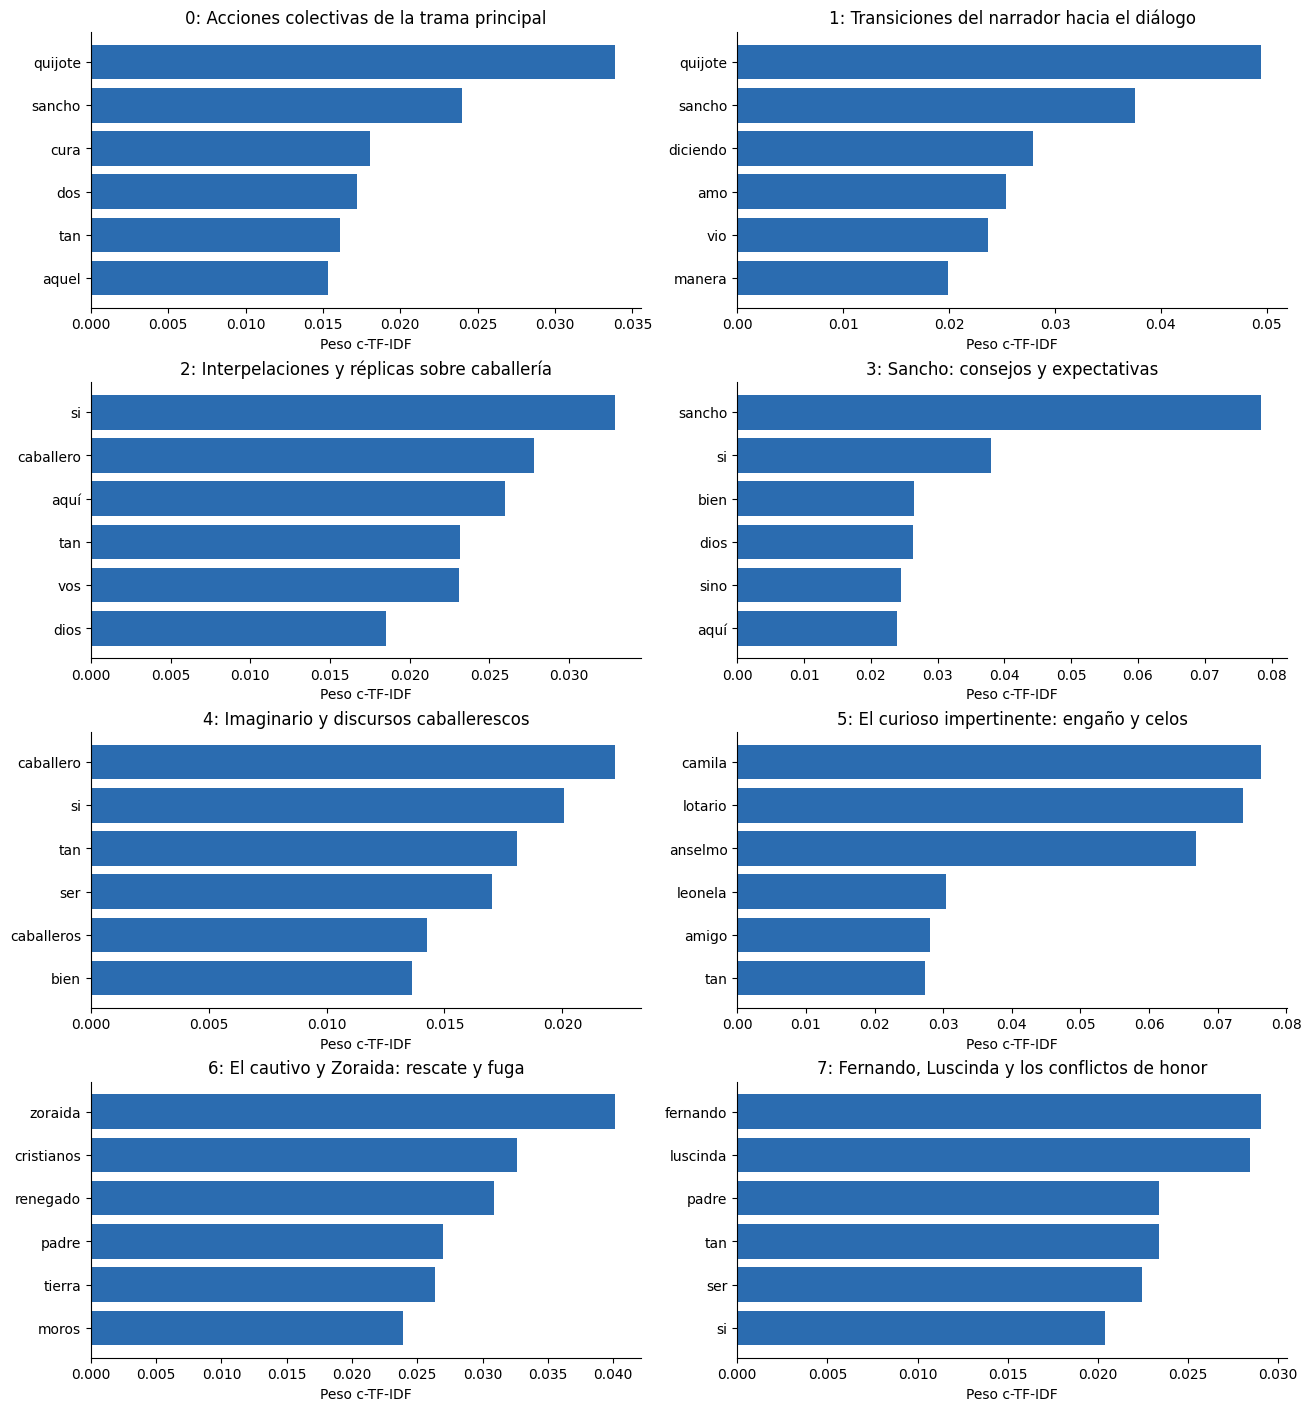

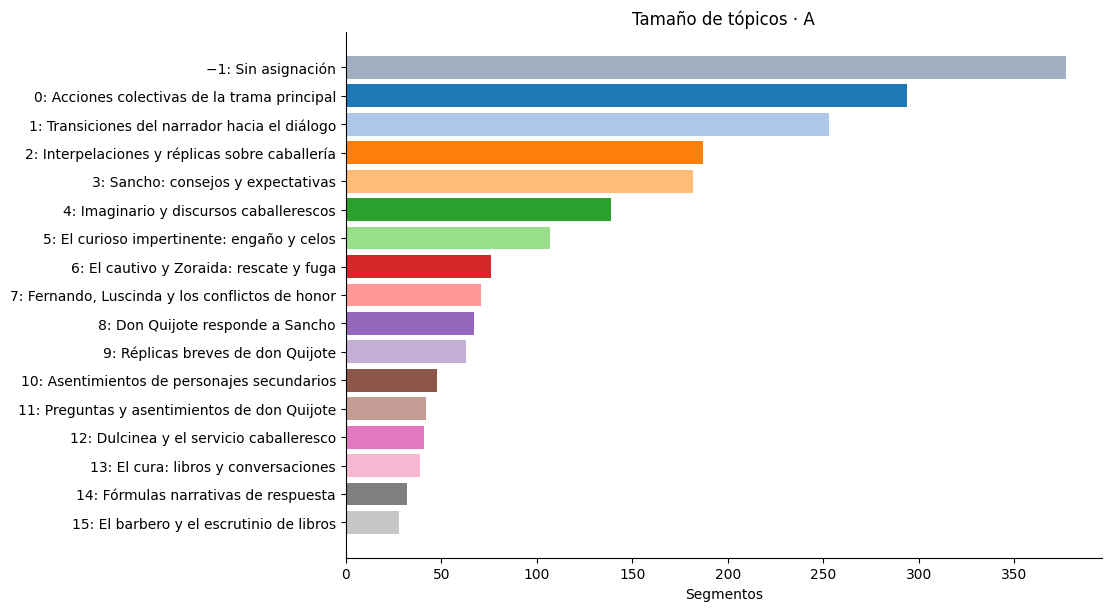

In [11]:
colors = plt.get_cmap("tab20")
fig, axes = plt.subplots(4, 2, figsize=(13, 14), layout="constrained")
for ax, topic in zip(axes.flat, tables["A"].query("Topic != -1").head(8).Topic):
    terms = models["A"].get_topic(topic)[:6][::-1]
    ax.barh([word for word, _ in terms], [weight for _, weight in terms], color="#2b6cb0")
    ax.set(title=f"{topic}: {names['A'][topic]}", xlabel="Peso c-TF-IDF")
fig.savefig(RESULTS / "palabras_A.png", dpi=150)
plt.show()

counts = segments.topic_A.value_counts().sort_values()
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ax.barh([f"{t}: {names['A'][t]}" if t != -1 else "−1: Sin asignación" for t in counts.index],
        counts.values, color=[colors(t % 20) if t != -1 else "#a0aec0" for t in counts.index])
ax.set(xlabel="Segmentos", title="Tamaño de tópicos · A")
fig.savefig(RESULTS / "tamanos_A.png", dpi=150)
plt.show()

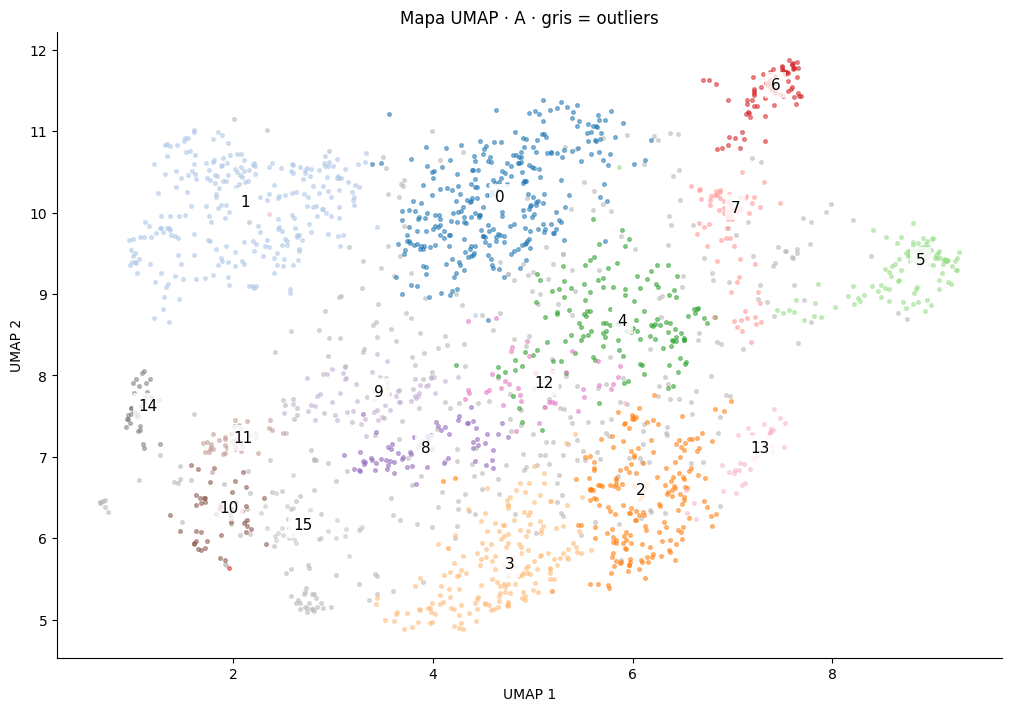

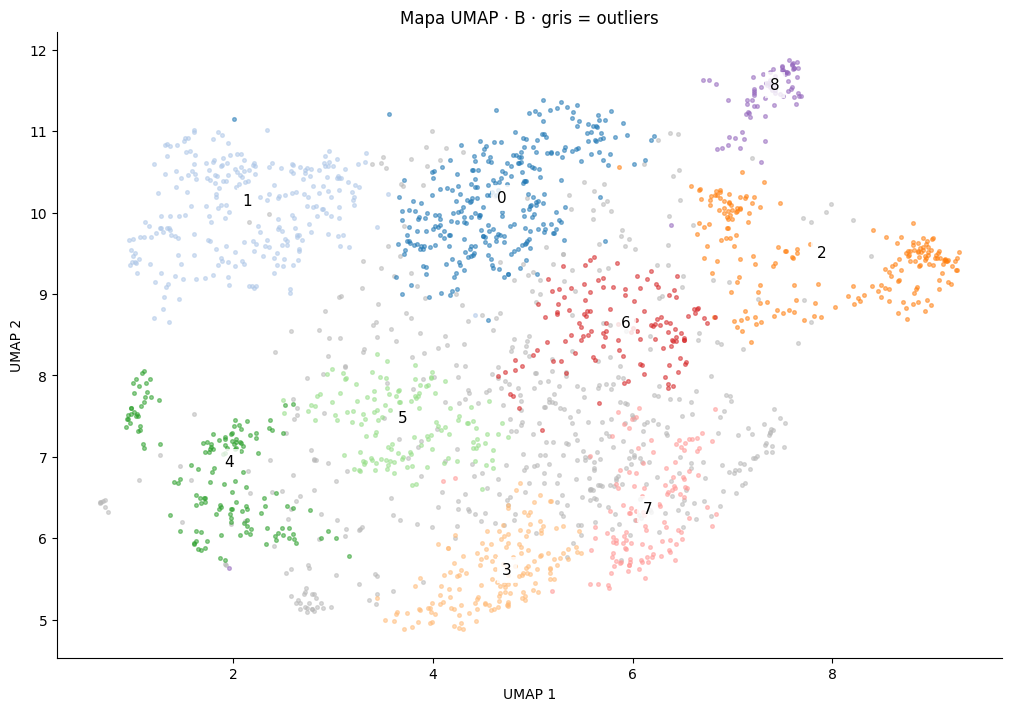

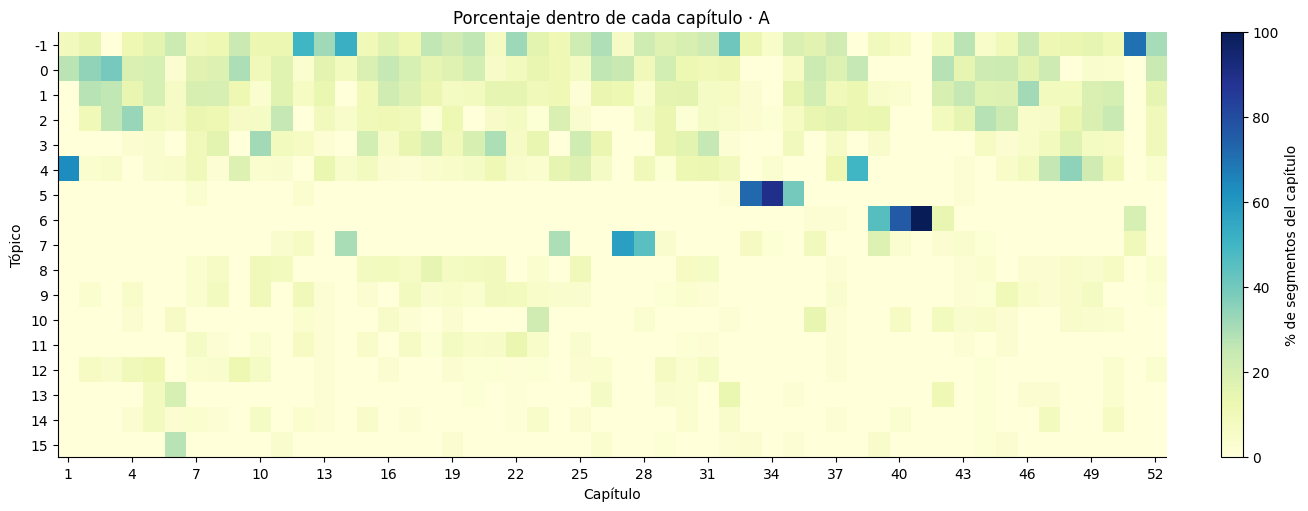

In [12]:
# Las coordenadas se calculan una vez y se comparten entre A y B.
projection = UMAP(n_neighbors=15, n_components=2, min_dist=.15,
                  metric="cosine", random_state=SEED, n_jobs=1).fit_transform(embeddings)
for config in configs:
    topics = segments[f"topic_{config}"].to_numpy()
    fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
    for topic in sorted(set(topics)):
        points = projection[topics == topic]
        ax.scatter(points[:, 0], points[:, 1], s=7, alpha=.5,
                   color=colors(topic % 20) if topic != -1 else "#b8b8b8")
        if topic != -1:
            ax.annotate(str(topic), np.median(points, axis=0), fontsize=11,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=.8))
    ax.set(title=f"Mapa UMAP · {config} · gris = outliers", xlabel="UMAP 1", ylabel="UMAP 2")
    fig.savefig(RESULTS / f"mapa_{config}.png", dpi=160)
    plt.show()

chapter_topics = pd.crosstab(segments.topic_A, segments.chapter, normalize="columns") * 100
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
image = ax.imshow(chapter_topics, aspect="auto", cmap="YlGnBu", vmin=0, vmax=100)
ax.set_yticks(range(len(chapter_topics)), chapter_topics.index)
ax.set_xticks(range(0, 52, 3), chapter_topics.columns[::3])
ax.set(xlabel="Capítulo", ylabel="Tópico", title="Porcentaje dentro de cada capítulo · A")
fig.colorbar(image, ax=ax, label="% de segmentos del capítulo")
fig.savefig(RESULTS / "capitulos_A.png", dpi=160)
plt.show()

## 6. Comparación e interpretación

La tabla de cruces relaciona los identificadores de A y B; esos números no tienen el mismo significado entre modelos.
ARI mide acuerdo entre particiones, no exactitud temática.

In [13]:
display(pd.crosstab(segments.topic_A, segments.topic_B))
common = (segments.topic_A != -1) & (segments.topic_B != -1)
print("ARI incluyendo outliers:", round(adjusted_rand_score(segments.topic_A, segments.topic_B), 3))
print("Inliers compartidos:", int(common.sum()))
print("ARI sobre inliers compartidos:", round(adjusted_rand_score(
    segments.loc[common, "topic_A"], segments.loc[common, "topic_B"]), 3))
print("Outliers (%):", {c: round(100 * (segments[f'topic_{c}'] == -1).mean(), 2) for c in configs})

topic_B,-1,0,1,2,3,4,5,6,7,8
topic_A,,,,,,,,,,
-1,313,10,4,22,0,8,11,7,0,2
0,11,283,0,0,0,0,0,0,0,0
1,0,0,253,0,0,0,0,0,0,0
2,65,0,0,0,0,0,0,0,122,0
3,23,0,0,0,158,0,0,0,1,0
4,19,1,0,0,0,0,0,119,0,0
5,0,0,0,107,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,76
7,0,0,0,71,0,0,0,0,0,0


ARI incluyendo outliers: 0.648
Inliers compartidos: 1460
ARI sobre inliers compartidos: 0.911
Outliers (%): {'A': np.float64(18.43), 'B': np.float64(25.51)}


**Se elige A como configuración principal para interpretar el contenido.** Distingue *El curioso impertinente* (A5) del conflicto amoroso de Fernando y Luscinda (A7), conserva el grupo del cautivo (A6) y deja fuera menos segmentos. Sus 16 tópicos exigen más lectura que los nueve de B y varios son patrones de estilo. B ofrece una síntesis más corta, pero su mayor silhouette (0.0637 frente a 0.0539) no compensa por sí sola esa pérdida de detalle: ambas cifras indican separación débil en el espacio original. No hay evidencia de que una configuración sea universalmente superior.

B aumenta los outliers de 377 a 522: **145 segmentos más y 7.09 puntos porcentuales**. Exigir grupos más grandes no garantiza mayor cobertura. La tabla de cruces muestra que 209 inliers de A pasan a −1 en B, mientras 64 outliers de A sí reciben grupo en B. Por eso no es correcto describir B como una simple fusión de los grupos de A.

El acuerdo ajustado entre particiones (ARI) es 0.648 incluyendo −1 y 0.911 sobre los 1,460 segmentos que son inliers en ambas. El segundo valor sugiere que buena parte de las asignaciones centrales se conserva, pero excluye precisamente los casos cuya aceptación cambia. Es acuerdo entre configuraciones, no una medida de exactitud.

### Visualización 1: barras de palabras y tamaños


Las palabras de **A5** —Camila, Lotario, Anselmo y Leonela— permiten reconocer *El curioso impertinente*. **A6** combina Zoraida, cristianos, renegado, barca y moros: la lectura de sus ejemplos confirma una historia de cautiverio y fuga. En contraste, A0 y A1 contienen Quijote, Sancho y fórmulas generales que aparecen en muchos episodios. Una barra alta es un peso descriptivo c-TF-IDF, no una probabilidad de pertenencia ni el número de menciones en toda la novela.


A0 tiene 294 segmentos (14.37%) y A1, 253 (12.37%): son los dos grupos mayores y, sin embargo, no son los dos más específicos. El grupo −1 reúne 377 (18.43%) y supera a cualquier tópico individual. El tamaño permite medir cobertura, pero no coherencia. El catálogo conserva los tópicos pequeños para poder discutirlos, en vez de esconderlos tras el gráfico de los ocho más grandes.

En B, «quijote quijote» aparece entre los términos de B4. Al construir c-TF-IDF, BERTopic concatena textos del mismo grupo; un bigrama puede cruzar el límite entre dos documentos después de retirar stopwords. La comprobación da cero ocurrencias de ese bigrama al analizar cada segmento de B4 por separado y seis al concatenarlos. Este es un artefacto de representación: no debe interpretarse como una expresión literaria recurrente. Los n-gramas cambiaron las descripciones, no la geometría de los embeddings usada por HDBSCAN.

### Visualización 2: mapa UMAP de segmentos



En A, el grupo 5 aparece concentrado a la derecha y el 6 en la zona superior derecha, mientras que 0 y 1 ocupan regiones más amplias. A14 forma una pequeña zona compacta a la izquierda: sus ejemplos muestran que corresponde a fórmulas de respuesta y no a un tema literario.

Los mapas usan **las mismas coordenadas** y cambian únicamente el color según A o B. Se observan zonas concentradas y una región más mezclada, coherentes con la coexistencia de relatos específicos y parlamentos comunes a toda la novela. Las fórmulas breves también pueden formar manchas compactas: la cercanía geométrica no las convierte en temas de contenido. En B, varios grupos pequeños de A se agrupan o pasan a gris; la correspondencia se comprueba con la tabla de cruces, no solamente con la imagen.

UMAP 2D puede distorsionar distancias; ni la orientación de los ejes ni la separación visual prueban una oposición literaria. El clustering se entrenó en cinco dimensiones, no sobre estos mapas de dos dimensiones. Los rótulos enlazan con los identificadores de las tablas; los colores son identificadores, sin orden semántico.

### Visualización 3: tópicos a lo largo de los capítulos


La concentración de **A5 en los capítulos 33–35** aporta evidencia contextual: 103 de sus 107 segmentos (96.3%) están en ese tramo. **A6** tiene 67 de sus 76 segmentos (88.2%) en los capítulos 39–41, donde se relata el cautiverio. Esos dos grupos tienen sentido como episodios reconocibles. A0 y A1 se reparten por muchos capítulos, compatible con sus nombres amplios de acciones y transiciones del narrador.

Cada columna está normalizada sobre los segmentos de su capítulo, incluyendo −1. Un capítulo corto y uno largo pueden mostrar el mismo porcentaje con cantidades distintas. La continuidad temporal no prueba por sí sola coherencia, pero ayuda a comprobar que los nombres propuestos coinciden con la ubicación de los ejemplos.

### Tópicos que tienen sentido y agrupaciones que fallan

Los resultados más interpretables son **A5, A6 y A7**: palabras, ejemplos y localización apuntan a relatos identificables. A4 también permite hablar del imaginario caballeresco, aunque incluye reflexiones sobre libros y fantasías de don Quijote. A3 sigue la perspectiva de Sancho, una agrupación más ligada al personaje que a un único asunto.

Los grupos **A10, A11 y A14** tienen medianas de 8, 8.5 y 7 palabras. Sus ejemplos centrales son afirmaciones como «Así es», preguntas cortas o «A lo cual respondió don Quijote». Pasan el mínimo de cinco palabras porque incluyen el marcador de hablante, pero aportan poco contexto temático. En B se concentran en B4, cuya mediana es de ocho palabras. Eliminar duplicados exactos no elimina variantes casi idénticas. Estos grupos se explican por la estructura del diálogo y la longitud, y no se presentan como descubrimientos literarios.

**A12** tiene relación con Dulcinea y el servicio a damas, pero todos sus 41 segmentos pasan a −1 en B; **A13**, centrado en el cura, pierde también sus 39 segmentos. Esto evidencia sensibilidad a los parámetros. Para una mejora posterior convendría comparar la unidad párrafo con una variante que incorpore contexto adyacente a intervenciones muy cortas, dejando explícito que cambiaría la unidad exigida en esta entrega. También podría evaluarse una lista ampliada de conectores frecuentes y una representación que evite bigramas entre documentos. Esos cambios no se aplicaron aquí y no se les atribuye una mejora no medida.

Un ejemplo importante de −1 es **P1-C01-S0001**, el célebre inicio «En un lugar de la Mancha…»: queda sin asignación en ambas configuraciones, aunque es esencial para la novela. Su descripción de la vida cotidiana no forma un grupo denso suficiente. Esto muestra por qué outlier no equivale a texto inútil y justifica conservarlo en los datos y porcentajes.

## Tratamiento de los outliers

A conserva **377 de 2046 segmentos (18.43%)** como −1;
B conserva **522 (25.51%)**. No se eliminan ni se reasignan.
Son una señal de densidad insuficiente o ambigüedad; no prueba de texto malo ni de irrelevancia literaria.
Los catálogos contienen tres ejemplos de −1 por configuración para inspección. Se evita forzar su incorporación a temas
porque cambiaría la cobertura a costa de asignaciones sin validación. Como trabajo posterior se podría probar
`reduce_outliers` con un umbral de coseno, comparar antes/después y revisar manualmente las reasignaciones.
Ese experimento no se ejecutó y sus efectos no se presuponen.

## Límites y fuentes

El español del Siglo de Oro contiene grafías y sentidos distintos del español contemporáneo utilizado por el encoder.
Los nombres propios pueden dominar grupos de personajes y episodios; esto no demuestra el descubrimiento de temas
literarios abstractos como justicia o idealismo. La novela tiene continuidad y relatos intercalados, por lo que los segmentos
no son independientes. Las frecuencias son de segmentos, no de palabras, lectores o toda la obra de Cervantes.
El modelo asigna un solo tópico por fragmento aunque este contenga varias ideas.

La semilla fija controla UMAP, pero las versiones y plataforma también influyen. Las versiones principales están fijadas en `requirements.txt` y la revisión del encoder aparece en este notebook. La implementación y la interpretación
se elaboraron con asistencia de IA; no existe una evaluación humana independiente ni métricas de exactitud.

Fuentes: [corpus](https://www.gutenberg.org/ebooks/2000),
[encoder E5](https://huggingface.co/intfloat/multilingual-e5-small),
[reproducibilidad de BERTopic](https://maartengr.github.io/BERTopic/getting_started/best_practices/best_practices.html),
[outliers](https://maartengr.github.io/BERTopic/getting_started/outlier_reduction/outlier_reduction.html),
[repositorio consultado](https://github.com/ErikJajan/BERTopic).